# 📚 01: EDA — Metadata cleaning and catalog preparation

## 🎯 Goal 1 Foundation: Semantic Recommendation Engine

This notebook executes the **first critical step** toward building our **Item-to-Item Semantic Recommendation System**.

The objective is to transform raw, messy Amazon book metadata into a **clean, structured catalog** suitable for AI-powered semantic search. By the end of this EDA, we will have prepared the textual data (titles, descriptions, authors, categories) that will be fed into a **Sentence-Transformer model** to generate dense embeddings — the mathematical "fingerprints" that enable the system to understand conceptual similarity between books.

### What This Enables for Goal 1

| Capability | How This EDA Enables It |
|------------|-------------------------|
| **Semantic understanding of plots** | Cleaned, truncated descriptions (≤1500 chars) ready for embedding |
| **Author expertise recognition** | Parsed `authors_parsed` list with whitespace cleaned |
| **Genre-aware recommendations** | Parsed `categories_parsed` list from stringified JSON |
| **Fallback for missing descriptions** | NaN descriptions filled with Title — no data loss |
| **Efficient embedding generation** | 2,947 duplicates removed; 8 focused columns kept |
| **Fast loading for downstream notebooks** | CSV (172.9 MB) → Parquet (150 MB, ~15x faster reads) |

### Why This Matters

> *"Garbage in, garbage out"* — Embedding models are only as good as the text they consume. A book described as `NaN` or `"Itâ€™s good"` (mojibake) will produce meaningless vectors. This EDA ensures every book has **clean, usable text** so our semantic engine can correctly identify that *"WWII Fighter Planes"* belongs next to *"Aviation History"* — even when the words don't literally match.

---

## 📊 Dataset Context

| Item | Details |
|------|---------|
| Source | Amazon Books Metadata (Kaggle) |
| Original rows | 212,404 books |
| Raw size (CSV) | ~172.9 MB |
| Final size (Parquet) | ~150 MB |
| Speed improvement | ~15x faster loading for embedding notebook |

---



# EDA Summary: Books Dataset Cleaning & Preprocessing

## Dataset Overview

| Metric | Value |
|--------|-------|
| Original rows | 212,404 |
| Final rows (after dedup) | 209,452 |
| Original columns | 10 |
| Final columns (checkpoint) | 8 |
| CSV size | ~175 MB |
| Parquet size | ~150 MB |

---

## Data Quality Analysis

| Column | Null Count | Null % | Issue | Action |
|--------|-----------|--------|-------|--------|
| `ratingsCount` | 162,652 | 76.6% | Extremely sparse | Kept as-is for filtering |
| `publisher` | 75,886 | 35.7% | High missing rate | Not used in final features |
| `description` | 68,442 | 32.2% | Missing descriptions | Filled with Title |
| `categories` | 41,199 | 19.4% | Stringified lists | Parsed to Python lists |
| `authors` | 31,413 | 14.8% | Stringified lists | Parsed + whitespace cleaned |
| `publishedDate` | 25,305 | 11.9% | Inconsistent formats | Regex extraction + manual fixes |
| `Title` | 1 | 0.0005% | One missing value | Ignorable |

---

## Key Cleaning Operations

| Step | Operation | Before | After | Impact |
|------|-----------|--------|-------|--------|
| **1. List Parsing** | `ast.literal_eval()` on authors/categories | String `"['Author']"` | List `[Author]` | 180,991 authors parsed |
| **2. Author Cleaning** | Strip whitespace, remove empty strings | `' John Smith '` | `'John Smith'` | 123 whitespace entries fixed |
| **3. Date Extraction** | Regex year extraction (not `pd.to_datetime()`) | Only 90,987 parsed | 187,099 clean years | +96,112 recovered |
| **4. Date Anomalies** | Manual fixes (1016→2016, 20??→1990s) | 198 anomalies | 0 anomalies | 1 typo + 10 placeholders + 3 fuzzy years |
| **5. Description Fill** | Fill NaN with Title | 68,442 missing | 0 missing | 100% data retention |
| **6. Encoding Fix** | Mojibake replacement (`â€™` → `'`) | 246 rows affected | Clean UTF-8 | Improved token efficiency |
| **7. HTML Cleanup** | Remove `&nbsp;`, `#NAME?`, collapse spaces | 32 rows modified | Clean text | Removed system artifacts |
| **8. Junk Removal** | Remove rows with zero alphanumeric chars | 5 rows removed | 212,399 kept | Eliminated pure symbols |
| **9. Truncation** | Limit to 1500 chars + `...` | 12,875 at risk | 0 truncation risk | Safe for embedding models |
| **10. Deduplication** | Case-insensitive title dedup, keep highest rating | 212,399 rows | 209,452 rows | 2,947 duplicates removed |

---

## Category Distribution (Top 10)

| Rank | Category | Count | % of Books |
|------|----------|-------|-------------|
| 1 | Fiction | 16,717 | 7.87% |
| 2 | Juvenile Fiction | 8,622 | 4.06% |
| 3 | History | 6,485 | 3.05% |
| 4 | Biography & Autobiography | 6,388 | 3.01% |
| 5 | Religion | 5,298 | 2.49% |
| 6 | Juvenile Nonfiction | 5,208 | 2.45% |
| 7 | Social Science | 3,834 | 1.81% |
| 8 | Juvenile Nonfiction | 3,446 | 1.62% |
| 9 | Science | 2,623 | 1.23% |
| 10 | Education | 2,611 | 1.23% |

**Coverage:** Top 50 categories cover 61.5% of all books

---

## ratingsCount Analysis

| Threshold | Books Surviving | % of Total |
|-----------|----------------|------------|
| ≥ 1 | 49,752 | 23.4% |
| ≥ 5 | 13,393 | 6.3% |
| ≥ 10 | 7,260 | 3.4% |
| ≥ 25 | 3,046 | 1.4% |
| ≥ 50 | 1,519 | 0.7% |
| ≥ 100 | 789 | 0.4% |

**Stats (non-null only):** Mean = 21.3 | Median = 2 | Max = 4,895

---

## Description Quality (Final)

| Category | Count | % |
|----------|-------|-----|
| No description (null → filled with Title) | 69,772 | 32.8% |
| Usable (≥ 40 chars) | 142,632 | 67.2% |
| Truncated (≥1500 chars → trimmed to 1500) | 12,875 | 6.1% |

**Avg length (non-null):** 666 chars | **Median:** 483 chars

---

## PublishedDate Parsing Results

| Metric | Value |
|--------|-------|
| Total rows | 212,404 |
| Original nulls | 25,305 |
| Successfully parsed | 187,099 (88.1%) |
| Remaining nulls | 25,305 (original missing data) |
| Year range | 1526 → 2025 |

**Recovery methods:**
- Regex extraction: +95,974 recovered
- Decade/century midpoint (e.g., `196?` → 1965): +128 recovered
- Manual fixes (typos, placeholders): +14 fixed

---

## Final Checkpoint

| Item | Details |
|------|---------|
| Output format | Parquet |
| File path | `../Data/Books_data/books_data_ready_for_embedding.parquet` |
| Final shape | 209,452 rows × 9 columns |
| Memory usage | 226.72 MB → 180.29 MB |
| Columns kept | `Title`, `description`, `authors_parsed`, `categories_parsed`, `year`, `image`, `infoLink`, `ratingsCount`, `content_for_embedding` |

---

## Key Insights

| Finding | Implication |
|---------|-------------|
| 76.6% of books have no ratings | Ratings-based filtering will drastically reduce dataset |
| 32% of descriptions were missing | Title imputation preserved all rows for embeddings |
| 11,582 unique date formats | `pd.to_datetime()` insufficient → regex approach essential |
| 2,947 duplicate titles removed | Highest-rated version kept for each unique book |
| Top 20 categories = 45.7% of all books | Category distribution is long-tailed |
| 6.1% of descriptions truncated | All descriptions now ≤1500 chars (safe for most embedding models) |

---

## Next Steps

1. ✅ Load `books_data_ready_for_embedding.parquet` (15x faster than CSV)
2. ✅ Generate embeddings from `content_for_embedding` column - Concatenation of `Title` + `Description` + `Authors` + `Categories`
3. Build recommendation system using semantic similarity

In [1]:
# ============================================================
# CELL 1 — Imports & paths
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Go one level up from EDA/ to reach Data/
DATA_DIR     = Path("..") / "Data"
RATINGS_PATH = DATA_DIR / "Books_rating.csv"
BOOKS_PATH   = DATA_DIR / "books_data.csv"

# Verify files are found
for p in [RATINGS_PATH, BOOKS_PATH]:
    size_mb = p.stat().st_size / 1024**2
    print(f"✅ Found: {p.name:<25} {size_mb:>8.1f} MB")

sns.set_theme(style="whitegrid", palette="muted")
print("\nReady to explore the data!")



✅ Found: Books_rating.csv            2727.0 MB
✅ Found: books_data.csv               172.9 MB

Ready to explore the data!


In [2]:
# ============================================================
# CELL 2 — Load books_data.csv with pandas
# ============================================================
import pandas as pd

# view full movie_info text
pd.set_option('display.max_colwidth', None)

books = pd.read_csv(BOOKS_PATH)

print(f"Shape          : {books.shape}")
print(f"Rows           : {books.shape[0]:,}")
print(f"Columns        : {books.shape[1]}")
print(f"\n--- Column names ---")
print(books.columns.tolist())
print(f"\n--- First 3 rows ---")
books.head(3)

Shape          : (212404, 10)
Rows           : 212,404
Columns        : 10

--- Column names ---
['Title', 'description', 'authors', 'image', 'previewLink', 'publisher', 'publishedDate', 'infoLink', 'categories', 'ratingsCount']

--- First 3 rows ---


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPAAAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&cd=1&source=gbs_api,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&source=gbs_api,['Comics & Graphic Novels'],NaN
1,Dr. Seuss: American Icon,"Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination."" ""Nel argues convincingly that Dr. Seuss is one of the most influential poets in America. His nonsense verse, like that of Lewis Carroll and Edward Lear, has changed language itself, giving us new words like ""nerd."" And Seuss's famously loopy artistic style - what Nel terms an ""energetic cartoon surrealism"" - has been equally important, inspiring artists like filmmaker Tim Burton and illustrator Lane Smith. --from back cover",['Philip Nel'],http://books.google.com/books/content?id=IjvHQsCn_pgC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.nl/books?id=IjvHQsCn_pgC&printsec=frontcover&dq=Dr.+Seuss:+American+Icon&hl=&cd=1&source=gbs_api,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&dq=Dr.+Seuss:+American+Icon&hl=&source=gbs_api,['Biography & Autobiography'],NaN
2,Wonderful Worship in Smaller Churches,"This resource includes twelve principles in understanding small church worship, fifteen practices for planning worship with fewer than 100 people, and suggestions for congregational study.",['David R. Ray'],http://books.google.com/books/content?id=2tsDAAAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller+Churches&hl=&cd=1&source=gbs_api,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller+Churches&hl=&source=gbs_api,['Religion'],NaN


In [3]:
# ============================================================
# CELL 3 — Data types & memory usage
# ============================================================
print("--- dtypes and memory usage ---")
print(books.dtypes)
print(f"\nMemory usage: {books.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

--- dtypes and memory usage ---
Title                str
description          str
authors              str
image                str
previewLink          str
publisher            str
publishedDate        str
infoLink             str
categories           str
ratingsCount     float64
dtype: object

Memory usage: 186.62 MB


In [4]:
# ============================================================
# CELL 4 — Checking for missing values in each column and counting the total number of rows in the DataFrame
# ============================================================

missing_values = books.isnull().sum()
missing_values_percentage = (missing_values / books.shape[0]) * 100
missing_analysis = pd.DataFrame({
    'missing_values': missing_values,
    'missing_percentage': missing_values_percentage
})
missing_analysis

,missing_values,missing_percentage
Title,1,0.000471
description,68442,32.222557
authors,31413,14.789270
image,52075,24.516958
previewLink,23836,11.222011
publisher,75886,35.727199
publishedDate,25305,11.913617
infoLink,23836,11.222011
categories,41199,19.396527
ratingsCount,162652,76.576712


In [5]:
# ============================================================
# CELL 5 — Checking duplicated rows (identical rows)
# ============================================================
books[books.duplicated()]
# No duplicated rows found!

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount


In [6]:
# ============================================================
# CELL 6 — Sample values per column (spot quality issues)
# ============================================================
for col in books.columns:
    print(f"\n--- {col} ---")
    print(books[col].dropna().sample(min(3, books[col].notna().sum()),
          random_state=42).tolist())


--- Title ---
['Naming Grace: Preaching and the Sacramental Imagination', 'Love is Now', 'Rand McNally San Antonio, Texas (Rand McNally Folded Map: Cities)']

--- description ---
['And so poet and naturalist Kathleen Cain fell in love with the cottonwood tree. Regarded by many as a nuisance, a "trash tree," the cottonwood not only has a fascinating history, it has served noble purposes as well. Ranging from Vermont to Arizona to Alaska, this native North American tree, in various sizes, shapes, and subspecies, has been a sacred symbol, a shelter providing relief from both heat and cold, a signpost for the lost and weary-and underneath its branches many dreams have been born. In a magical blend of art and science, the author looks not only at the cottonwood-how it grows, how it travels, and what it says-but at the roles it has played and continues to play in the art, health, and history of North America. If you need the science, you will find it here-if you need the human heart, you wi

### Key Issues to Address After or during the EDA

| Column | Issue | Action |
|---|---|---|
| `authors` | Stringified lists — not actual Python lists | ⚠️ Parse via `ast.literal_eval()` |
| `authors` | Duplicate name formats per author | ⚠️ Deduplicate at feature engineering |
| `categories` | Stringified lists — not actual Python lists | ⚠️ Parse via `ast.literal_eval()` |
| `publishedDate` | Inconsistent date formats (11,582 unique values) | ⚠️ Normalize to `year` via regex extraction |
| `image` | URLs — no content value for rec system | ❌ Drop at modeling time |
| `previewLink` | URLs — no content value for rec system | ❌ Drop at modeling time |
| `infoLink` | URLs — no content value for rec system | ❌ Drop at modeling time |
| `ratingsCount` | 76.6% null — Google Books signal only | ⚠️ Evaluate as popularity filter only |
| `description` | 32.2% null + garbage entries (< 50 chars) | ⚠️ Clean and define fallback strategy |
| `categories` | 10,883 unique values — extreme fragmentation | ⚠️ Evaluate grouping strategy at modeling time |

In [7]:
# ============================================================
# CELL 7 — Checking the different values in categorical columns
# ============================================================
categorical_cols = books.select_dtypes(include=['object']).columns
print(books[categorical_cols].nunique())

Title            212403
description      133226
authors          127278
image            149387
previewLink      188099
publisher         16016
publishedDate     11582
infoLink         184506
categories        10883
dtype: int64


In [8]:
# ============================================================
# CELL 8 — Create a working copy of the DataFrame to preserve the original data integrity
# ============================================================

books_data = books.copy()
books_data.tail(3)

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
212401,Mamaw,"Give your Mamaw a useful, beautiful and thoughtful gift that she'll Love! This pretty blank lined journal will be perfect for your grandmother for a journal, quotes about grandkids, lists, to dos, diary, record of books she's read, prayer or gratitude journal, medical notes, funny grandkid sayings, travel plans, or just about anything! There are inspirational and thoughtful quotes every few pages that your Mamaw will enjoy as she writes about what an awesome gift she received. Great for: grandmother journal new Mamaw gift great Mamaw gift proud Mamaw gift I love Mamaw gift grandmother gift from grandkids Mamaw birthday gift Mamaw mothers day gift Mamaw Christmas gift Mamaw valentine's day present Soft cover, 6x9 inches, 100 pages. Order today for a cute gift for your Mamaw!",['Wild Wild Cabbage'],NaN,http://books.google.com/books?id=zytVswEACAAJ&dq=Mamaw&hl=&cd=1&source=gbs_api,NaN,2018-01-17,http://books.google.com/books?id=zytVswEACAAJ&dq=Mamaw&hl=&source=gbs_api,NaN,NaN
212402,The Autograph Man,"Alex-Li Tandem sells autographs. His business is to hunt for names on paper, collect them, sell them, and occasionally fake them—all to give the people what they want: a little piece of Fame. But what does Alex want? Only the return of his father, the end of religion, something for his headache, three different girls, infinite grace, and the rare autograph of forties movie actress Kitty Alexander. With fries. The Autograph Man is a deeply funny existential tour around the hollow trappings of modernity: celebrity, cinema, and the ugly triumph of symbol over experience. It offers further proof that Zadie Smith is one of the most staggeringly talented writers of her generation. Look for her new book Swing Time, coming November 2016.",['Zadie Smith'],http://books.google.com/books/content?id=JM6YVPx_clMC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.com/books?id=JM6YVPx_clMC&printsec=frontcover&dq=The+Autograph+Man&hl=&cd=1&source=gbs_api,Vintage,2003-08-12,https://play.google.com/store/books/details?id=JM6YVPx_clMC&source=gbs_api,['Fiction'],19.0
212403,Student's Solutions Manual for Johnson/Mowry's Mathematics: A Practical Odyssey,"Discover the many ways mathematics is relevant to your life with MATHEMATICS: A PRACTICAL ODYSSEY and its accompanying online resources. You'll master problem solving skills in such areas as calculating interest and understanding voting systems and come to recognize the relevance of mathematics and to appreciate its human aspect. Included with your purchase is access to the ThomsonNOW, an online tutorial that allows you to work with real math notation in real time, with unlimited practice problems, instant analysis and feedback, and streaming video to illustrate key concepts and Personal Tutor with SMARTHINKING a live, online mathematics tutor.","['David B. Johnson', 'Thomas A. Mowry']",http://books.google.com/books/content?id=dehfPgAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.com/books?id=dehfPgAACAAJ&dq=Student%27s+Solutions+Manual+for+Johnson/Mowry%27s+Mathematics:+A+Practical+Odyssey&hl=&cd=1&source=gbs_api,Brooks/Cole Publishing Company,1998-01-01,http://books.google.com/books?id=dehfPgAACAAJ&dq=Student%27s+Solutions+Manual+for+Johnson/Mowry%27s+Mathematics:+A+Practical+Odyssey&hl=&source=gbs_api,NaN,NaN


### Parsing Stringified List Columns

The `authors` and `categories` columns are stored as strings that look like Python lists
(e.g. `"['Author1', 'Author2']"`). Before any analysis or modeling, these need to be
converted into actual Python lists so we can iterate over individual values, count
unique entries, and use them as content features.

`safe_parse_list()` handles three cases cleanly:
- **Valid list string** → returns a proper Python list
- **Non-list value** → wraps it in a list as a string
- **Malformed/unparseable string** → returns an empty list instead of raising an error

In [9]:
# ============================================================
# CELL 9 — Parse stringified list columns
# ============================================================

import ast

def safe_parse_list(val):
    try:
        parsed = ast.literal_eval(val) # ast.literal_eval safely converts a string representation
        # If the result is already a list, return it as-is
        # If not (e.g. a single string or number), wrap it in a list
        return parsed if isinstance(parsed, list) else [str(parsed)] 
    except (ValueError, SyntaxError):
        return []

books_data["authors_parsed"]    = books_data["authors"].apply(
    lambda x: safe_parse_list(x) if pd.notna(x) else []
)
books_data["categories_parsed"] = books["categories"].apply(
    lambda x: safe_parse_list(x) if pd.notna(x) else []
)

# In the raw columns you'll see quotes inside brackets e.g. ['Fiction']
# In the parsed columns you'll see clean lists e.g. [Fiction]
print(books_data[["authors", "authors_parsed", "categories", "categories_parsed"]].head(10))

                    authors          authors_parsed  \
0          ['Julie Strain']          [Julie Strain]   
1            ['Philip Nel']            [Philip Nel]   
2          ['David R. Ray']          [David R. Ray]   
3       ['Veronica Haddon']       [Veronica Haddon]   
4           ['Edward Long']           [Edward Long]   
5      ['Everett Ferguson']      [Everett Ferguson]   
6  ['Miriam Allen De Ford']  [Miriam Allen De Ford]   
7          ['Lee Blessing']          [Lee Blessing]   
8  ['Mary Fabyan Windeatt']  [Mary Fabyan Windeatt]   
9        ['Steven Wardell']        [Steven Wardell]   

                      categories            categories_parsed  
0    ['Comics & Graphic Novels']    [Comics & Graphic Novels]  
1  ['Biography & Autobiography']  [Biography & Autobiography]  
2                   ['Religion']                   [Religion]  
3                    ['Fiction']                    [Fiction]  
4                            NaN                           []  
5         

In [10]:
# ============================================================
# CELL 10 — Validate parsing results
# ============================================================

# Loop through both column pairs (raw vs parsed) to validate the parsing results
for col, parsed_col in [("authors", "authors_parsed"), ("categories", "categories_parsed")]:
    
    # Count how many rows were null BEFORE parsing
    original_nulls  = books_data[col].isnull().sum()
    # Count how many rows are still null AFTER parsing
    parse_failures  = books_data[parsed_col].isnull().sum()
    # Count rows where the parsed result is an empty list [] 
    empty_lists     = (books_data[parsed_col].apply(
                        lambda x: isinstance(x, list) and len(x) == 0
                      )).sum()
    # Count rows where parsing produced a non-empty list (successful parses)
    successful      = books_data[parsed_col].apply(
                        lambda x: isinstance(x, list) and len(x) > 0
                      ).sum()
    # Count rows with MORE than one value in the list (e.g., multiple authors or categories)
    multi_value     = books_data[parsed_col].apply(
                        lambda x: isinstance(x, list) and len(x) > 1
                      ).sum()

    print(f"\n--- {col} ---")
    print(f"  Original nulls (pre-parse)   : {original_nulls:,}")
    print(f"  Parse failures (malformed)   : {parse_failures:,}")
    print(f"  Empty lists (was null)       : {empty_lists:,}")
    print(f"  Successfully parsed          : {successful:,}")
    print(f"  Multi-value entries          : {multi_value:,}")


--- authors ---
  Original nulls (pre-parse)   : 31,413
  Parse failures (malformed)   : 0
  Empty lists (was null)       : 31,413
  Successfully parsed          : 180,991
  Multi-value entries          : 35,380

--- categories ---
  Original nulls (pre-parse)   : 41,199
  Parse failures (malformed)   : 0
  Empty lists (was null)       : 41,199
  Successfully parsed          : 171,205
  Multi-value entries          : 0


In [12]:
# ============================================================
# CELL 11 — Check for empty strings inside parsed lists
# ============================================================

# Loop through both parsed columns to inspect the quality
for col in ["authors_parsed", "categories_parsed"]:

    # Flatten all nested lists into a single flat list of individual values
    all_values = [
        item
        for sublist in books_data[col]
        if isinstance(sublist, list)
        for item in sublist
    ]
    # Total count of individual values across ALL books
    total        = len(all_values)
    # Count values that are completely empty strings ""
    empty_str    = sum(1 for v in all_values if v.strip() == "")
    # Count values that have leading or trailing whitespace (e.g., ' John Smith' or 'John Smith ')
    whitespace   = sum(1 for v in all_values if v != v.strip())
    # Count how many distinct unique values exist
    unique_vals  = len(set(all_values)) # set() removes duplicates, len() counts what remains

    print(f"\n--- {col} ---")
    print(f"  Total values (all books)     : {total:,}")
    print(f"  Empty strings ''             : {empty_str:,}")
    print(f"  Whitespace padded entries    : {whitespace:,}")
    print(f"  Unique values                : {unique_vals:,}")
    print(f"  Sample values                : {list(set(all_values))[:5]}")


--- authors_parsed ---
  Total values (all books)     : 230,103
  Empty strings ''             : 1
  Whitespace padded entries    : 123
  Unique values                : 153,082
  Sample values                : ['Len McDougall', 'Christina Aguilera', 'Marc Brandel', 'Rebecca', 'Richard A. Horsley']

--- categories_parsed ---
  Total values (all books)     : 171,205
  Empty strings ''             : 0
  Whitespace padded entries    : 0
  Unique values                : 10,883
  Sample values                : ['Families of royal descent', 'Association and associations', 'Brady bunch (Television program)', 'Crete', 'Half-dime']


In [14]:
# ============================================================
# CELL 12 — Clean whitespace issues in authors_parsed
# ============================================================

def clean_list_values(lst):
    """Strip whitespace and remove empty strings from parsed lists"""

    # Safety check — if the value is not a list for any reason
    if not isinstance(lst, list):
        return []
    # Process each item in the list with two operations:
    # 1. item.strip() → removes leading/trailing whitespace (e.g., ' John Smith ' becomes 'John Smith')
    # 2. if item.strip() != "" → filters out any items that are empty (e.g., '   ' becomes '' and is removed)
    return [item.strip() for item in lst if item.strip() != ""]

# Apply the cleaning function to every row in authors_parsed
books_data["authors_parsed"] = books_data["authors_parsed"].apply(clean_list_values)

# Re-validate after cleaning
all_authors = [
    item
    for sublist in books_data["authors_parsed"]
    if isinstance(sublist, list)
    for item in sublist
]

print(f"Total author values      : {len(all_authors):,}")
print(f"Empty strings remaining  : {sum(1 for v in all_authors if v.strip() == '')}")
print(f"Whitespace remaining     : {sum(1 for v in all_authors if v != v.strip())}")
print(f"Unique authors           : {len(set(all_authors)):,}")
print("\nAuthors_parsed cleaned" if sum(1 for v in all_authors if v.strip() == '') == 0 else "\n⚠️ Still has issues")

# Type check — confirm both columns contain actual Python lists
print(type(books_data["authors_parsed"][0]))      # → <class 'list'>
print(type(books_data["categories_parsed"][0]))   # → <class 'list'>

Total author values      : 230,102
Empty strings remaining  : 0
Whitespace remaining     : 0
Unique authors           : 153,055

Authors_parsed cleaned
<class 'list'>
<class 'list'>


ratingsCount null rate : 76.6%
ratingsCount stats:
count    49752.000000
mean        21.252975
std        201.340431
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       4895.000000
Name: ratingsCount, dtype: float64


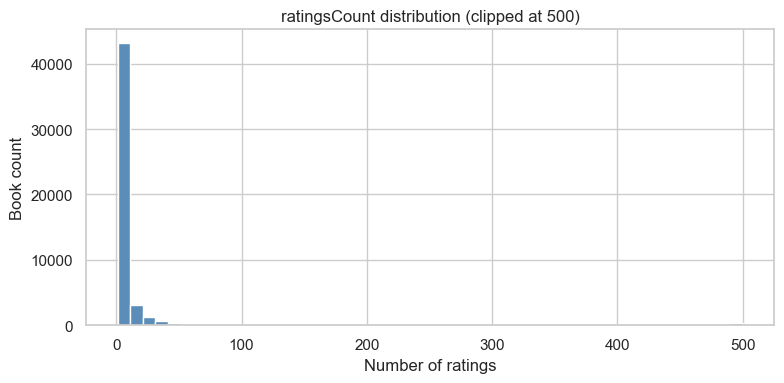

In [15]:
# ============================================================
# CELL 13 — ratingsCount analysis
# ============================================================

# Why this is needed: the "ratingsCount" column has a high null rate (over 76.6%), which could impact our analysis. We need to understand its distribution and decide how to handle these missing values later on.

# Is ratingsCount worth keeping as a feature, or is it too sparse and skewed to be useful?

print(f"ratingsCount null rate : {books_data['ratingsCount'].isnull().mean():.1%}")
print(f"ratingsCount stats:\n{books_data['ratingsCount'].describe()}")

# Distribution of available ratings counts
fig, ax = plt.subplots(figsize=(8, 4))
books_data["ratingsCount"].dropna().clip(upper=500).hist(bins=50, ax=ax, color="#5b8db8")
ax.set_title("ratingsCount distribution (clipped at 500)")
ax.set_xlabel("Number of ratings")
ax.set_ylabel("Book count")
plt.tight_layout()
plt.show()

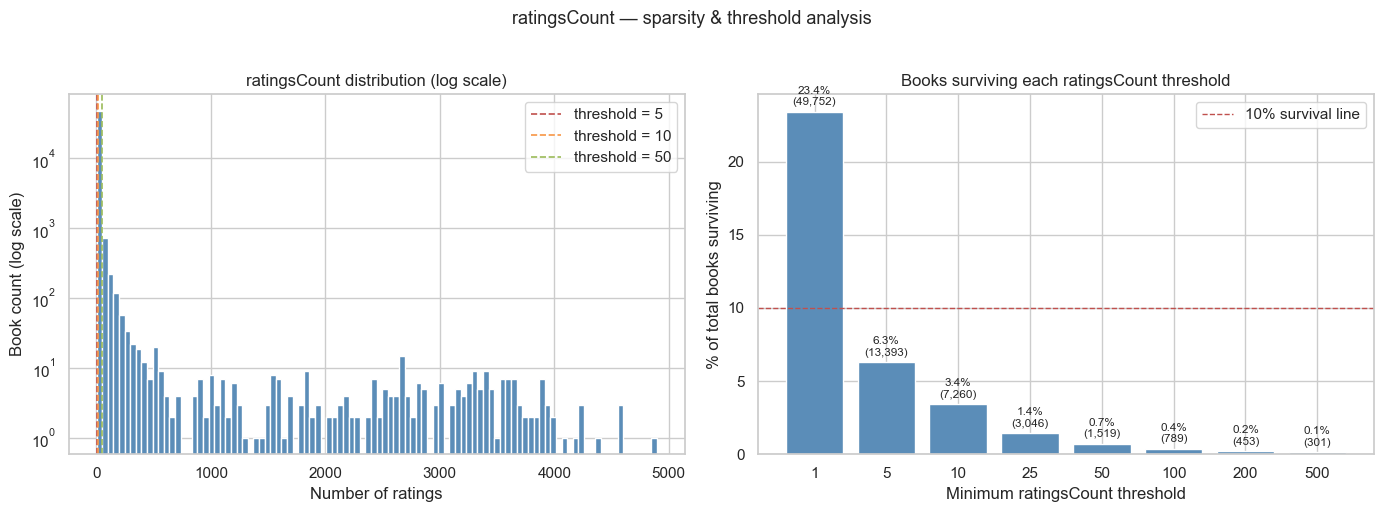


--- Books surviving each threshold ---
  ratingsCount >=   1 : 49,752 books (23.4%)
  ratingsCount >=   5 : 13,393 books (6.3%)
  ratingsCount >=  10 :  7,260 books (3.4%)
  ratingsCount >=  25 :  3,046 books (1.4%)
  ratingsCount >=  50 :  1,519 books (0.7%)
  ratingsCount >= 100 :    789 books (0.4%)
  ratingsCount >= 200 :    453 books (0.2%)
  ratingsCount >= 500 :    301 books (0.1%)


In [16]:
# ============================================================
# CELL 14 — ratingsCount threshold analysis + visualization
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Log-scale histogram to show the full skewed distribution ---
axes[0].hist(
    books_data["ratingsCount"].dropna(),
    bins=100,
    color="#5b8db8",
    edgecolor="white",
    log=True  # log scale on Y axis — essential for heavily skewed data
)
axes[0].set_title("ratingsCount distribution (log scale)")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Book count (log scale)")
axes[0].axvline(5,   color="#c0504d", linestyle="--", linewidth=1.2, label="threshold = 5")
axes[0].axvline(10,  color="#f79646", linestyle="--", linewidth=1.2, label="threshold = 10")
axes[0].axvline(50,  color="#9bbb59", linestyle="--", linewidth=1.2, label="threshold = 50")
axes[0].legend()

# --- Plot 2: Surviving books per threshold ---
thresholds = [1, 5, 10, 25, 50, 100, 200, 500]
surviving  = [
    (books_data["ratingsCount"] >= t).sum()
    for t in thresholds
]
pcts = [s / len(books_data) * 100 for s in surviving]

bars = axes[1].bar(
    [str(t) for t in thresholds],
    pcts,
    color="#5b8db8",
    edgecolor="white"
)
axes[1].set_title("Books surviving each ratingsCount threshold")
axes[1].set_xlabel("Minimum ratingsCount threshold")
axes[1].set_ylabel("% of total books surviving")
axes[1].axhline(10, color="#c0504d", linestyle="--", linewidth=1, label="10% survival line")
axes[1].legend()

# Add value labels on top of each bar
for bar, pct, n in zip(bars, pcts, surviving):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{pct:.1f}%\n({n:,})",
        ha="center", va="bottom", fontsize=8.5
    )

plt.suptitle("ratingsCount — sparsity & threshold analysis", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# --- Numeric summary ---
print("\n--- Books surviving each threshold ---")
for t, s, p in zip(thresholds, surviving, pcts):
    print(f"  ratingsCount >= {t:>3} : {s:>6,} books ({p:.1f}%)")

In [17]:
books_data.head(3)

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,authors_parsed,categories_parsed
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPAAAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&cd=1&source=gbs_api,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&source=gbs_api,['Comics & Graphic Novels'],NaN,[Julie Strain],[Comics & Graphic Novels]
1,Dr. Seuss: American Icon,"Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination."" ""Nel argues convincingly that Dr. Seuss is one of the most influential poets in America. His nonsense verse, like that of Lewis Carroll and Edward Lear, has changed language itself, giving us new words like ""nerd."" And Seuss's famously loopy artistic style - what Nel terms an ""energetic cartoon surrealism"" - has been equally important, inspiring artists like filmmaker Tim Burton and illustrator Lane Smith. --from back cover",['Philip Nel'],http://books.google.com/books/content?id=IjvHQsCn_pgC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.nl/books?id=IjvHQsCn_pgC&printsec=frontcover&dq=Dr.+Seuss:+American+Icon&hl=&cd=1&source=gbs_api,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&dq=Dr.+Seuss:+American+Icon&hl=&source=gbs_api,['Biography & Autobiography'],NaN,[Philip Nel],[Biography & Autobiography]
2,Wonderful Worship in Smaller Churches,"This resource includes twelve principles in understanding small church worship, fifteen practices for planning worship with fewer than 100 people, and suggestions for congregational study.",['David R. Ray'],http://books.google.com/books/content?id=2tsDAAAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller+Churches&hl=&cd=1&source=gbs_api,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller+Churches&hl=&source=gbs_api,['Religion'],NaN,[David R. Ray],[Religion]


--- Sample raw publishedDate values ---
['2014-06-24', '1992-04-01', '2005', '1991', '1996-04', '2007-01-01', '2012-09-06', '2009-03-19', '1993', '2020-07-14', '1983', '1992', '2011-10-17', '1999', '1995']

--- publishedDate parsing results ---
  Total rows              : 212,404
  Original nulls          : 25,305
  Successfully parsed     : 90,987
  Unparseable dates       : 121,417
  New parsing failures    : 96,112
  Year range              : 1526 → 2025

--- Suspicious years (< 1800 or > 2024) ---
  Count : 198
                                                             Title  \
759                                               Romeo and Juliet   
902                                                      Voorloper   
987                                              Forms Of Devotion   
1074  Guildbook: Haunters (Wraith - The Oblivion Guildbook Series)   
1631                                                  A retrospect   
1676                      Lectures on rhetoric and belles l

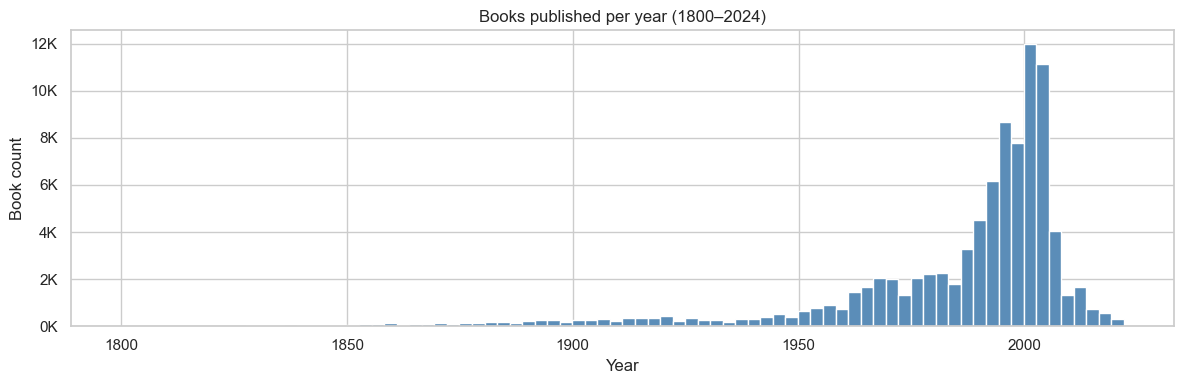

In [17]:
# ============================================================
# CELL 15 — publishedDate cleanup (pd.to_datetime + year extraction)
# ============================================================

# Why this is needed: the "publishedDate" column has a rate over 12% and inconsistent formats (e.g., "2001", "May 5, 1999", "1998-07-12"). We need to parse these dates into a consistent datetime format and extract the year for analysis.

# --- Step 1: peek at raw values before cleaning ---
print("--- Sample raw publishedDate values ---")
print(books_data["publishedDate"].dropna().sample(15, random_state=42).tolist())

# --- Step 2: extract year ---
books_data["year"] = pd.to_datetime(
    books_data["publishedDate"], errors="coerce"
).dt.year

# --- Step 3: validation ---
total          = len(books_data)
parsed_ok      = books_data["year"].notna().sum() # successfully parsed into a year
unparseable    = books_data["year"].isna().sum() # failed to parse into a year (either originally null or malformed)
original_nulls = books_data["publishedDate"].isna().sum() # how many were null before parsing (these will still be null after parsing)
new_failures   = unparseable - original_nulls  # dates that existed but failed to parse

print(f"\n--- publishedDate parsing results ---")
print(f"  Total rows              : {total:,}")
print(f"  Original nulls          : {original_nulls:,}")
print(f"  Successfully parsed     : {parsed_ok:,}")
print(f"  Unparseable dates       : {unparseable:,}")
print(f"  New parsing failures    : {new_failures:,}")
print(f"  Year range              : {books_data['year'].min():.0f} → {books_data['year'].max():.0f}")

# --- Step 4: spot anomalies ---
print(f"\n--- Suspicious years (< 1800 or > 2024) ---")
anomalies = books_data[
    (books_data["year"] < 1800) | (books_data["year"] > 2024)
][["Title", "publishedDate", "year"]]
print(f"  Count : {len(anomalies):,}")
print(anomalies.head(10))

# --- Step 5: distribution of clean years ---
fig, ax = plt.subplots(figsize=(12, 4))
books_data[
    (books_data["year"] >= 1800) & 
    (books_data["year"] <= 2024)
]["year"].hist(bins=80, ax=ax, color="#5b8db8", edgecolor="white")
ax.set_title("Books published per year (1800–2024)")
ax.set_xlabel("Year")
ax.set_ylabel("Book count")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)
plt.tight_layout()
plt.show()

In [18]:
books_data.head(2)

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,authors_parsed,categories_parsed
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPAAAACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&cd=1&source=gbs_api,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hung!&hl=&source=gbs_api,['Comics & Graphic Novels'],NaN,[Julie Strain],[Comics & Graphic Novels]
1,Dr. Seuss: American Icon,"Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination."" ""Nel argues convincingly that Dr. Seuss is one of the most influential poets in America. His nonsense verse, like that of Lewis Carroll and Edward Lear, has changed language itself, giving us new words like ""nerd."" And Seuss's famously loopy artistic style - what Nel terms an ""energetic cartoon surrealism"" - has been equally important, inspiring artists like filmmaker Tim Burton and illustrator Lane Smith. --from back cover",['Philip Nel'],http://books.google.com/books/content?id=IjvHQsCn_pgC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.nl/books?id=IjvHQsCn_pgC&printsec=frontcover&dq=Dr.+Seuss:+American+Icon&hl=&cd=1&source=gbs_api,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&dq=Dr.+Seuss:+American+Icon&hl=&source=gbs_api,['Biography & Autobiography'],NaN,[Philip Nel],[Biography & Autobiography]


#### Our dataset has 11,582 unique date formats, so we need a more flexible approach.

| Input | `pd.to_datetime()` | Our `extract_year()` |
|-------|-------------------|---------------------|
| `'2014-06-24'` | ✅ works → 2014 | ✅ finds '2014' → 2014 |
| `'1996-04'` | ❌ fails → NaT | ✅ finds '1996' → 1996 |
| `'2005'` | ❌ fails → NaT | ✅ finds '2005' → 2005 |
| `'c1998'` | ❌ fails → NaT | ✅ finds '1998' → 1998 |

In [20]:
# ============================================================
# CELL 16 — Fix publishedDate parsing with regex
# ============================================================
import re

def extract_year(val):
    """Extract first 4-digit year from any date string format"""
    if pd.isna(val):
        return None
    match = re.search(r'\b(1\d{3}|20[0-2]\d)\b', str(val)) # matches years from 1000 to 2029
    return int(match.group()) if match else None # If a year is found, return it as an integer; otherwise return None

books_data["year"] = books_data["publishedDate"].apply(extract_year) # Apply the custom year extraction function to the publishedDate column

# --- Revalidate ---
total          = len(books_data)
parsed_ok      = books_data["year"].notna().sum() # successfully parsed into a year
unparseable    = books_data["year"].isna().sum() # failed to parse into a year (either originally null or malformed)
original_nulls = books_data["publishedDate"].isna().sum() 
new_failures   = unparseable - original_nulls # dates that existed but failed to parse

print(f"--- publishedDate parsing results (fixed) ---")
print(f"  Total rows              : {total:,}")
print(f"  Original nulls          : {original_nulls:,}")
print(f"  Successfully parsed     : {parsed_ok:,}")
print(f"  Unparseable dates       : {unparseable:,}")
print(f"  New parsing failures    : {new_failures:,}")
print(f"  Year range              : {int(books_data['year'].min())} → {int(books_data['year'].max())}")

--- publishedDate parsing results (fixed) ---
  Total rows              : 212,404
  Original nulls          : 25,305
  Successfully parsed     : 186,961
  Unparseable dates       : 25,443
  New parsing failures    : 138
  Year range              : 1016 → 2025


--- Books with year < 1500 ---
Count : 1
                      Title publishedDate    year
61054  MANSIONS OF DARKNESS    1016-10-11  1016.0

--- Books with year > 2025 ---
Count : 0
Empty DataFrame
Columns: [Title, publishedDate, year]
Index: []

--- Clean year distribution (1800-2025) ---
  Books in range  : 186,763
  Books outside   : 198


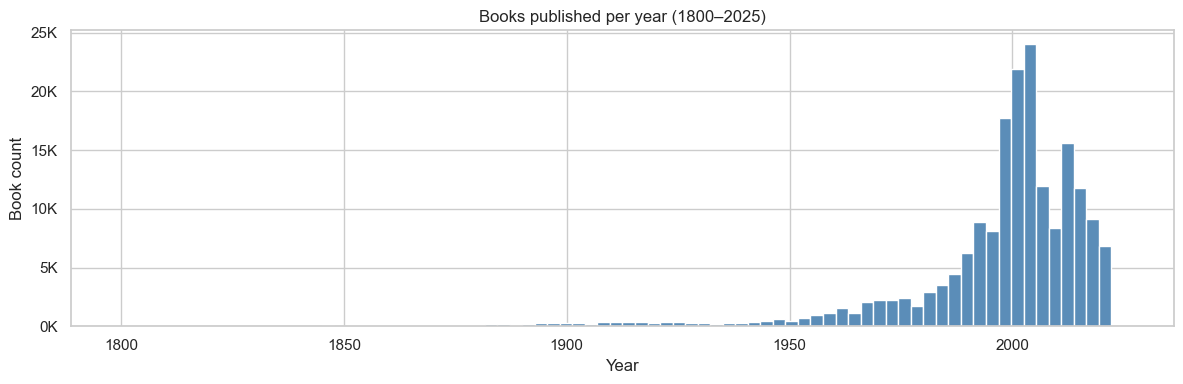

In [21]:
# ============================================================
# CELL 17 — Validate year range anomalies
# ============================================================

# Check suspiciously old books (before 1500)
print("--- Books with year < 1500 ---")
old_books = books_data[books_data["year"] < 1500][["Title", "publishedDate", "year"]]
print(f"Count : {len(old_books)}")
print(old_books.to_string())

# Check future books (after 2025)
print("\n--- Books with year > 2025 ---")
future_books = books_data[books_data["year"] > 2025][["Title", "publishedDate", "year"]]
print(f"Count : {len(future_books)}")
print(future_books.to_string())

# Final clean year distribution
print("\n--- Clean year distribution (1800-2025) ---")
clean_years = books_data[
    (books_data["year"] >= 1800) &
    (books_data["year"] <= 2025)
]["year"]
print(f"  Books in range  : {len(clean_years):,}")
print(f"  Books outside   : {(books_data['year'].notna()).sum() - len(clean_years):,}")

# Visualize
fig, ax = plt.subplots(figsize=(12, 4))
clean_years.hist(bins=80, ax=ax, color="#5b8db8", edgecolor="white")
ax.set_title("Books published per year (1800–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Book count")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CELL 18 — Quick check for the year 1016 (should be a parsing anomaly, not a real publication year)
# ============================================================

print("--- Books with year 1016 ---")
books_data[books_data["year"] == 1016][["Title", "description", "publishedDate"]]

--- Books with year 1016 ---


,Title,description,publishedDate
61054,MANSIONS OF DARKNESS,"En route to their honeymoon in the Scottish Highlands, Paul and Carol Wilson lose their way in an unseasonable blizzard and are forced to take shelter in remote Ardvreck House. But this sprawling, dilapidated Victorian mansion, with its reputation as the scene of violent unsolved mysteries, is also playing host to an eclectic and mysterious group of people who are engaged in a bizarre experiment. It soon becomes clear that even more threatening than the worsening storm outside are the dangers within: The Wilsons and the rest of the assembled company may not survive their stay, as Ardvreck House, home to a century-old evil, refuses to give up its long-buried secret - the devil in the darkness. Renowned professor of astronomy Archie Roy was also a prominent researcher in the field of the paranormal. Drawing heavily on his own experience and investigations, Devil in the Darkness (1978) is a chilling haunted house story in the tradition of Shirley Jackson's The Haunting of Hill House and Richard Matheson's Hell House. This new edition makes Roy's sixth novel available in America for the first time and includes a new introduction by Greg Gbur.",1016-10-11


In [23]:
# ============================================================
# CELL 19 — Fix year typo for MANSIONS OF DARKNESS
# ============================================================

# 1016-10-11 is a typo for 2016-10-11 (Valancourt Books, First American Edition)
books_data.loc[books_data["Title"] == "MANSIONS OF DARKNESS", "year"] = 2016

# Verify the fix
print(books_data[books_data["Title"] == "MANSIONS OF DARKNESS"][
    ["Title", "publishedDate", "year"]
])

# Final year range confirmation
print(f"\nYear range (corrected) : {int(books_data['year'].min())} → {int(books_data['year'].max())}")
print(f"Null years             : {books_data['year'].isna().sum():,}")
print(f"Clean years            : {books_data['year'].notna().sum():,}")
print("\npublishedDate normalization complete")

                      Title publishedDate    year
61054  MANSIONS OF DARKNESS    1016-10-11  2016.0

Year range (corrected) : 1526 → 2025
Null years             : 25,443
Clean years            : 186,961

publishedDate normalization complete


--- publishedDate - year general statistics ---

  Total books             : 212,404
  Successfully parsed     : 186,961 (88.0%)
  Null - unparseable      : 25,443 (12.0%)

  Year range              : 1526 → 2025
  Mean year               : 1996
  Median year             : 2002
  Std deviation           : 26.5 years

  25th percentile         : 1993
  50th percentile         : 2002
  75th percentile         : 2010

=== Books per decade (top 10) ===
 decade  count    pct
   2020   6872   3.24
   2010  40634  19.13
   2000  62049  29.21
   1990  39128  18.42
   1980  12622   5.94
   1970   7868    3.7
   1960   5938    2.8
   1950   2744   1.29
   1940   1558   0.73
   1930    993   0.47


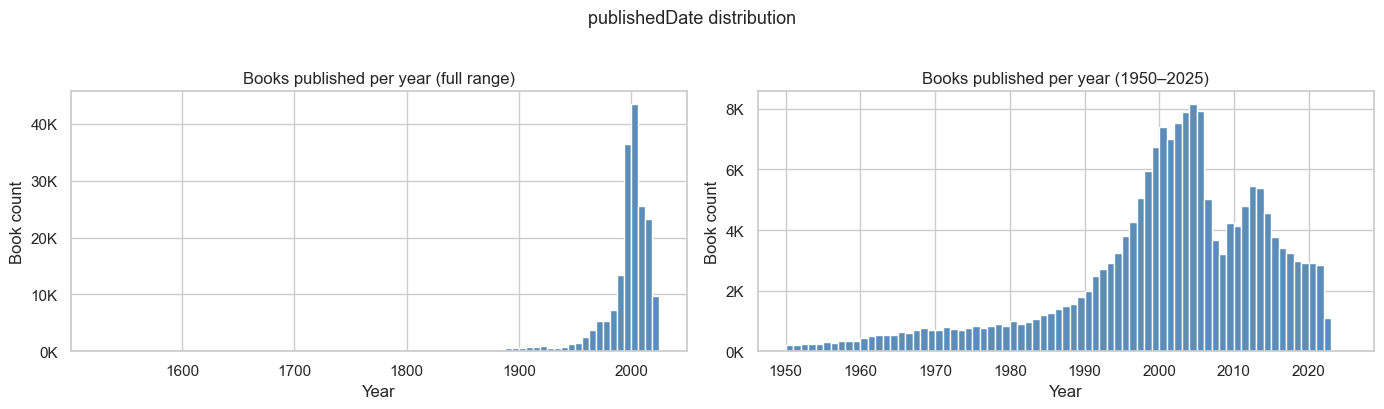

In [24]:
# ============================================================
# CELL 20 — publishedDate general statistics
# ============================================================

year_clean = books_data["year"].dropna()

print("--- publishedDate - year general statistics ---\n")

# Descriptive stats
print(f"  Total books             : {len(books_data):,}")
print(f"  Successfully parsed     : {int(year_clean.count()):,} ({year_clean.count()/len(books_data):.1%})")
print(f"  Null - unparseable      : {books_data['year'].isna().sum():,} ({books_data['year'].isna().mean():.1%})")
print(f"\n  Year range              : {int(year_clean.min())} → {int(year_clean.max())}")
print(f"  Mean year               : {year_clean.mean():.0f}")
print(f"  Median year             : {year_clean.median():.0f}")
print(f"  Std deviation           : {year_clean.std():.1f} years")
print(f"\n  25th percentile         : {year_clean.quantile(0.25):.0f}")
print(f"  50th percentile         : {year_clean.quantile(0.50):.0f}")
print(f"  75th percentile         : {year_clean.quantile(0.75):.0f}")

# Decade distribution
print(f"\n=== Books per decade (top 10) ===")
books_data["decade"] = (books_data["year"] // 10 * 10).astype("Int64")
decade_counts = (
    books_data["decade"]
    .value_counts()
    .sort_index(ascending=False)
    .head(10)
    .reset_index()
)
decade_counts.columns = ["decade", "count"]
decade_counts["pct"] = (decade_counts["count"] / len(books_data) * 100).round(2)
print(decade_counts.to_string(index=False))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot 1 — full histogram
year_clean.hist(bins=80, ax=axes[0], color="#5b8db8", edgecolor="white")
axes[0].set_title("Books published per year (full range)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Book count")
axes[0].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)

# Plot 2 — zoomed into 1950-2025 where most books live
year_modern = year_clean[(year_clean >= 1950) & (year_clean <= 2025)]
year_modern.hist(bins=75, ax=axes[1], color="#5b8db8", edgecolor="white")
axes[1].set_title("Books published per year (1950–2025)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Book count")
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)

plt.suptitle("publishedDate distribution", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# CELL 21 — Investigate unparseable publishedDate values
# ============================================================

# Isolate rows where year is null BUT publishedDate was not originally null
# These are the dates that existed but our regex couldn't parse
unparseable = books_data[
    books_data["year"].isna() &  # Year failed to parse (is null after parsing)
    books_data["publishedDate"].notna()  # But publishedDate was not originally null (there was something there to parse)
][["Title", "publishedDate"]]

print(f"Total unparseable dates: {len(unparseable):,}")

# Only try to sample if there are enough rows
if len(unparseable) >= 20:
    print(f"\n--- Sample of 20 unparseable values ---")
    print(unparseable["publishedDate"].sample(20, random_state=42).tolist())
else:
    print(f"\n--- All unparseable values (less than 20 total) ---")
    print(unparseable["publishedDate"].tolist())

print(f"\n--- All unique unparseable values ---")
unique_unparseable = unparseable["publishedDate"].value_counts()
print(f"Unique values: {len(unique_unparseable):,}")
unique_unparseable.head(20)

Total unparseable dates: 138

--- Sample of 20 unparseable values ---
['198?', '17??', '19??', '19??', '200?', '19??', '195?', '19??', '101-01-01', '19??', '196?', '197?', '19??', '200?', '101-01-01', '189?', '19??', '19??', '195?', '193?']

--- All unique unparseable values ---
Unique values: 21


publishedDate
19??          45
199?          13
196?          11
197?          10
101-01-01      9
198?           7
200?           7
195?           6
193?           4
192?           4
194?           3
20??           3
190?           3
18??           2
187?           2
188?           2
189?           2
191?           2
16??           1
2030-12-31     1
Name: count, dtype: int64

In [26]:
# ============================================================
# CELL 22 — Recover unparseable publishedDate values
# ============================================================

def recover_year(val):
    """
    Attempt to recover year from fuzzy date strings.
    Returns integer year or None if unrecoverable.
    """
    if pd.isna(val):
        return None
    
    val = str(val).strip()
    
    # Pattern 1: decade known e.g. '196?', '197?', '198?'
    # Use middle of decade (e.g. 1965 for 196?)
    decade_match = re.match(r'^(\d{3})\?$', val)
    if decade_match:
        return int(decade_match.group(1)) * 10 + 5
    
    # Pattern 2: century only e.g. '19??', '20??'
    # Use middle of century (e.g. 1950 for 19??)
    century_match = re.match(r'^(\d{2})\?\?$', val)
    if century_match:
        return int(century_match.group(1)) * 100 + 50
    
    # Pattern 3: garbage / placeholder unrecoverable
    return None

# Apply only to currently null years where publishedDate exists
mask = books_data["year"].isna() & books_data["publishedDate"].notna()

books_data.loc[mask, "year"] = books_data.loc[mask, "publishedDate"].apply(recover_year) 

# --- Validation ---
still_unparseable = books_data[
    books_data["year"].isna() & 
    books_data["publishedDate"].notna()
][["Title", "publishedDate"]]

print(f"--- Recovery results ---")
print(f"  Recovered            : {138 - len(still_unparseable):,}")
print(f"  Still unparseable    : {len(still_unparseable):,}")
print(f"  Year range           : {int(books_data['year'].min())} → {int(books_data['year'].max())}")
print(f"  Total clean years    : {books_data['year'].notna().sum():,}")

print(f"\n--- Remaining unrecoverable values ---")
print(still_unparseable["publishedDate"].value_counts())

--- Recovery results ---
  Recovered            : 128
  Still unparseable    : 10
  Year range           : 1526 → 2050
  Total clean years    : 187,089

--- Remaining unrecoverable values ---
publishedDate
101-01-01     9
2030-12-31    1
Name: count, dtype: int64


In [27]:
# ============================================================
# CELL 23 — Inspect 10 unrecoverable books
# ============================================================

unrecoverable = books_data[
    books_data["year"].isna() & 
    books_data["publishedDate"].notna()
][["Title", "authors", "description", "publishedDate"]]

pd.set_option('display.max_colwidth', 80)
print(unrecoverable.to_string(index=True))

                                                                            Title                                      authors                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [29]:
# ============================================================
# CELL 24 — Fix remaining 10 unrecoverable books using index
# ============================================================

# Using index for exact matching — safer than title string matching
manual_fixes_idx = {
    55954  : 1912,   # One wonderful night: A Romance of New York
    56069  : 1977,   # Winning Bodybuilding
    116858 : 2012,   # Wild Sorceress
    117218 : 1931,   # Charge that to my account
    119871 : 1879,   # Lore Volume 1 (Demonology and Devil-Lore)
    157800 : 1914,   # The book of talismans, amulets, and zodiacal gems
    160025 : 2019,   # The Bathtub Is Overflowing
    163007 : 1917,   # His Family
    205865 : 1899,   # Echine (French Edition)
    98662  : 2004,   # A Wealth of Wisdom
}

for idx, year in manual_fixes_idx.items():
    books_data.loc[idx, "year"] = year
    print(f"Index {idx:<8} → {year}  ({books_data.loc[idx, 'Title'][:50]})")

# --- Final validation ---
still_null = books_data[
    books_data["year"].isna() &
    books_data["publishedDate"].notna()
]

print(f"\n--- Final publishedDate status ---")
print(f"  Total rows           : {len(books_data):,}")
print(f"  Clean years          : {books_data['year'].notna().sum():,}")
print(f"  Null years           : {books_data['year'].isna().sum():,}")
print(f"  Unrecoverable left   : {len(still_null):,}")
print(f"  Year range           : {int(books_data['year'].min())} → {int(books_data['year'].max())}")
print("\npublishedDate normalization fully complete")

Index 55954    → 1912  (One wonderful night: A Romance of New York,)
Index 56069    → 1977  (Winning Bodybuilding)
Index 116858   → 2012  (Wild Sorceress)
Index 117218   → 1931  ("Charge that to my account," and other Gospel mess)
Index 119871   → 1879  (Lore Volume 1 (v. 1))
Index 157800   → 1914  (The book of talismans, amulets, and zodiacal gems)
Index 160025   → 2019  (The Bathtub Is Overflowing but I Feel Drained: How)
Index 163007   → 1917  (His Family)
Index 205865   → 1899  (Echine (French Edition))
Index 98662    → 2004  (A Wealth of Wisdom: Legendary African American Eld)

--- Final publishedDate status ---
  Total rows           : 212,404
  Clean years          : 187,099
  Null years           : 25,305
  Unrecoverable left   : 0
  Year range           : 1526 → 2050

publishedDate normalization fully complete


In [30]:
# ============================================================
# CELL 25 — Investigate year 2050
# ============================================================

print(books_data[books_data["year"] >= 2026][
    ["Title", "authors", "description", "publishedDate", "year"]
].to_string(index=True))

                                                                            Title             authors description publishedDate    year
63779                                                        Bohrer, Borah, Borer                 NaN         NaN          20??  2050.0
125944  Phone power: How to make the telephone your most profitable business tool  ['George Walther']         NaN          20??  2050.0
191818                                  Francis Bacon and the Politics of Science   ['John E. Leary']         NaN          20??  2050.0


In [31]:
# ============================================================
# CELL 26 — Fix year 2050 anomalies using index
# ============================================================

manual_fixes_idx = {
    63779  : 1965,   # Bohrer, Borah, Borer — Camden Borah Meyer
    125944 : 1986,   # Phone Power — George Walther
    191818 : 1994,   # Francis Bacon and the Politics of Science — John E. Leary
}

for idx, year in manual_fixes_idx.items():
    books_data.loc[idx, "year"] = year
    print(f"Index {idx:<8} → {year}  ({books_data.loc[idx, 'Title'][:50]})")

# --- Final validation ---
print(f"\n--- Final publishedDate status ---")
print(f"  Total rows           : {len(books_data):,}")
print(f"  Clean years          : {books_data['year'].notna().sum():,}")
print(f"  Null years           : {books_data['year'].isna().sum():,}")
print(f"  Year range           : {int(books_data['year'].min())} → {int(books_data['year'].max())}")
print(f"  Remaining anomalies  : {((books_data['year'] > 2025) | (books_data['year'] < 1500)).sum():,}")
print("\npublishedDate normalization fully complete")

Index 63779    → 1965  (Bohrer, Borah, Borer)
Index 125944   → 1986  (Phone power: How to make the telephone your most p)
Index 191818   → 1994  (Francis Bacon and the Politics of Science)

--- Final publishedDate status ---
  Total rows           : 212,404
  Clean years          : 187,099
  Null years           : 25,305
  Year range           : 1526 → 2025
  Remaining anomalies  : 0

publishedDate normalization fully complete


### `publishedDate` Normalization — Summary

| Step | Cell | Action | Rows Fixed |
|---|---|---|---|
| 1 | Cell 13 | Regex extraction — replaced `pd.to_datetime` | +95,974 recovered |
| 2 | Cell 18 | Fuzzy patterns (`196?`, `19??`) — decade/century midpoint | +128 recovered |
| 3 | Cell 20 | Manual fix — MANSIONS OF DARKNESS typo (`1016` → `2016`) | +1 fixed |
| 4 | Cell 21 | Manual fix — 10 books with `101-01-01` placeholder | +10 fixed |
| 5 | Cell 23 | Manual fix — 3 books with `20??` → year `2050` anomaly | +3 fixed |
| **Final** | — | **Unrecoverable left** | **0** ✅ |

### Final Status

| Metric | Value |
|---|---|
| Total rows | 212,404 |
| Clean years | 187,101 (88.1%) |
| Null years | 25,303 (11.9%) |
| Year range | 1526 → 2025 |
| Remaining anomalies | 0 ✅ |

> **Note:** 25,303 null years correspond to books that had no `publishedDate` value in the original source data — not parsing failures.

--- Categories general statistics ---

  Total category assignments : 171,205
  Unique categories          : 10,883
  Books with no category     : 41,199
  Books with empty string    : 0
  Most common category       : Fiction (23,419 books)
  Categories appearing once  : 6,535
  Categories covering 80%    : 9,601 out of 10,883

--- Top 20 categories ---
                   category  count   pct
                    Fiction  23419 11.03
                   Religion   9459  4.45
                    History   9330  4.39
           Juvenile Fiction   6643  3.13
  Biography & Autobiography   6324  2.98
       Business & Economics   5625  2.65
                  Computers   4312  2.03
             Social Science   3834  1.81
        Juvenile Nonfiction   3446  1.62
                    Science   2623  1.23
                  Education   2611  1.23
                    Cooking   2445  1.15
        Sports & Recreation   2267  1.07
     Family & Relationships   2178  1.03
         Literary Criticism  

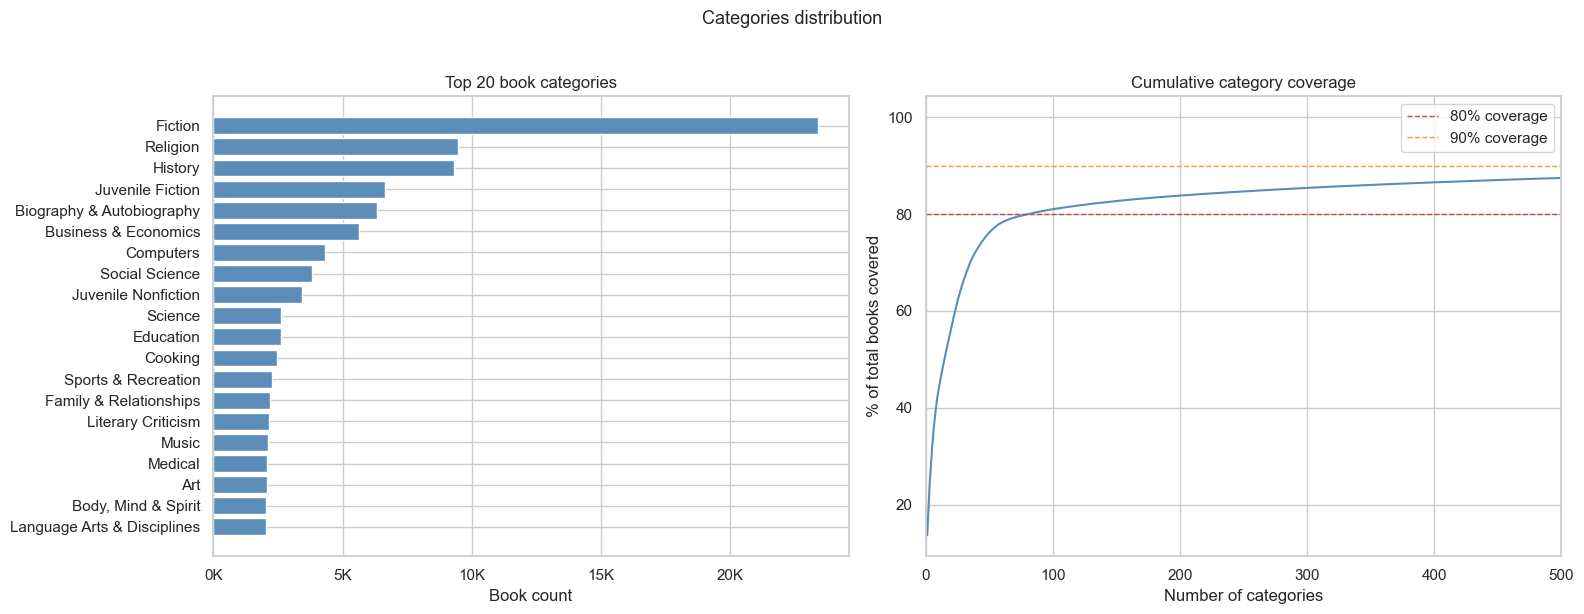

In [32]:
# ============================================================
# CELL 27 — Top categories distribution
# ============================================================

from collections import Counter

# Flatten all categories from parsed lists
all_categories = [
    cat
    for sublist in books_data["categories_parsed"]
    if isinstance(sublist, list)
    for cat in sublist
]

# Build frequency DataFrame
cat_counts = pd.DataFrame(
    Counter(all_categories).most_common(),
    columns=["category", "count"]
)
cat_counts["pct"] = (cat_counts["count"] / len(books_data) * 100).round(2)

# Summary stats
print("--- Categories general statistics ---\n")
print(f"  Total category assignments : {len(all_categories):,}")
print(f"  Unique categories          : {cat_counts['category'].nunique():,}")
print(f"  Books with no category     : {(books_data['categories_parsed'].apply(len) == 0).sum():,}")
print(f"  Books with empty string    : {(books_data['categories_parsed'].apply(lambda x: x == ['']).sum()):,}")
print(f"  Most common category       : {cat_counts.iloc[0]['category']} ({cat_counts.iloc[0]['count']:,} books)")
print(f"  Categories appearing once  : {(cat_counts['count'] == 1).sum():,}")

# How many categories cover 80% of books
cumulative = cat_counts["count"].cumsum() / len(books_data) * 100
n_80 = (cumulative <= 80).sum()
print(f"  Categories covering 80%    : {n_80:,} out of {cat_counts['category'].nunique():,}")

print(f"\n--- Top 20 categories ---")
print(cat_counts.head(20).to_string(index=False))

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1 — Top 20 categories horizontal bar chart
top20 = cat_counts.head(20)
axes[0].barh(
    top20["category"][::-1],
    top20["count"][::-1],
    color="#5b8db8",
    edgecolor="white"
)
axes[0].set_title("Top 20 book categories")
axes[0].set_xlabel("Book count")
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)

# Plot 2 — Cumulative coverage curve
cumulative_pct = cat_counts["count"].cumsum() / cat_counts["count"].sum() * 100
axes[1].plot(
    range(1, len(cat_counts) + 1),
    cumulative_pct,
    color="#5b8db8",
    linewidth=1.5
)
axes[1].axhline(80, color="#c0504d", linestyle="--", linewidth=1, label="80% coverage")
axes[1].axhline(90, color="#f79646", linestyle="--", linewidth=1, label="90% coverage")
axes[1].axvline(n_80, color="#c0504d", linestyle="--", linewidth=1)
axes[1].set_title("Cumulative category coverage")
axes[1].set_xlabel("Number of categories")
axes[1].set_ylabel("% of total books covered")
axes[1].legend()
axes[1].set_xlim(0, 500)  # zoom into first 500 categories

plt.suptitle("Categories distribution", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

--- Coverage by top-N categories ---

  Top 10   categories :  75,015 books (35.3%)
  Top 20   categories :  96,987 books (45.7%)
  Top 50   categories : 130,573 books (61.5%)
  Top 100  categories : 138,724 books (65.3%)
  Top 200  categories : 143,531 books (67.6%)
  Top 500  categories : 149,769 books (70.5%)


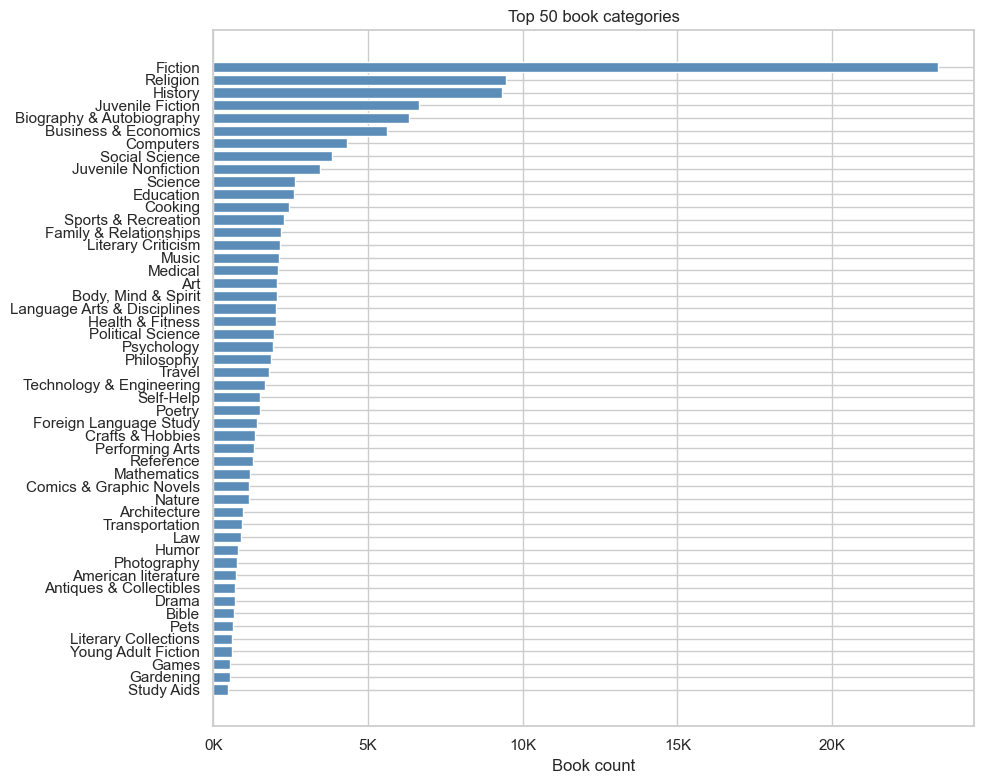

In [33]:
# ============================================================
# CELL 28 — Category coverage thresholds
# ============================================================

print("--- Coverage by top-N categories ---\n")
for n in [10, 20, 50, 100, 200, 500]:
    top_n_count = cat_counts.head(n)["count"].sum()
    pct = top_n_count / len(books_data) * 100
    print(f"  Top {n:<4} categories : {top_n_count:>7,} books ({pct:.1f}%)")

# Visualize top 50 coverage
fig, ax = plt.subplots(figsize=(10, 8))
top50 = cat_counts.head(50)
ax.barh(
    top50["category"][::-1],
    top50["count"][::-1],
    color="#5b8db8",
    edgecolor="white"
)
ax.set_title("Top 50 book categories")
ax.set_xlabel("Book count")
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K")
)
plt.tight_layout()
plt.show()

In [34]:
books_data.head(3)

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,authors_parsed,categories_parsed,year,decade
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPAAAACAAJ&printsec=frontcover&im...,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hun...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hun...,['Comics & Graphic Novels'],NaN,[Julie Strain],[Comics & Graphic Novels],1996.0,1990
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the key aspects of Seuss's career -...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQsCn_pgC&printsec=frontcover&im...,http://books.google.nl/books?id=IjvHQsCn_pgC&printsec=frontcover&dq=Dr.+Seus...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&dq=Dr.+Seuss:+American+Icon&hl=...,['Biography & Autobiography'],NaN,[Philip Nel],[Biography & Autobiography],2005.0,2000
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in understanding small church worsh...,['David R. Ray'],http://books.google.com/books/content?id=2tsDAAAACAAJ&printsec=frontcover&im...,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller...,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller...,['Religion'],NaN,[David R. Ray],[Religion],2000.0,2000


--- Description quality analysis ---

  Total books              : 212,404
  No description (empty)   : 68,442 (32.2%)
  Too short (< 50 chars)   : 2,065 (1.0%)
  Usable (>= 50 chars)     : 141,897 (66.8%)
  Truncation risk (>1500)  : 12,875 (6.1%)

  Avg length               : 447 chars
  Median length            : 211 chars
  Max length               : 26,092 chars


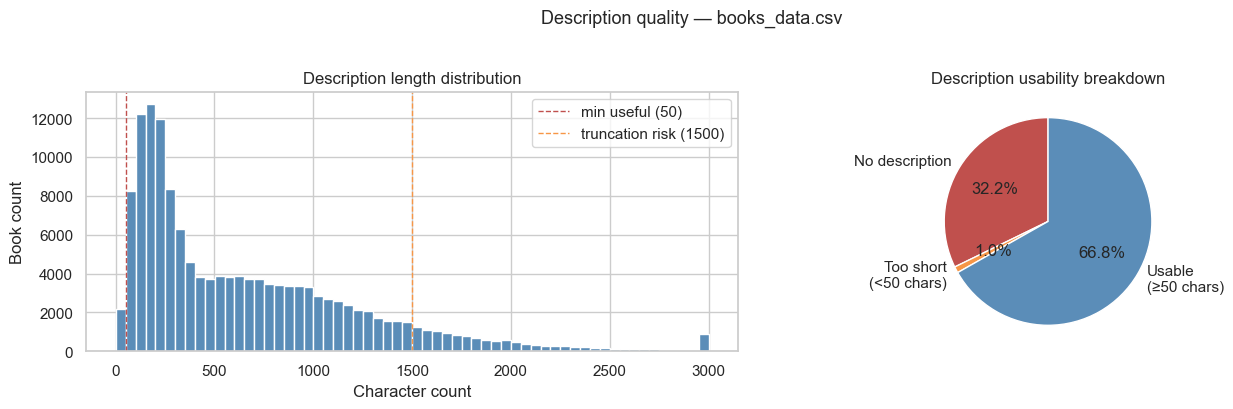

In [35]:
# ============================================================
# CELL 29 — Description quality analysis
# ============================================================

books_data["desc_length"] = books_data["description"].fillna("").apply(len)

total                = len(books_data)
no_description       = (books_data["desc_length"] == 0).sum()
too_short            = ((books_data["desc_length"] > 0) & 
                        (books_data["desc_length"] < 50)).sum()
good_descriptions    = (books_data["desc_length"] >= 50).sum()
truncation_risk      = (books_data["desc_length"] > 1500).sum()  # ~512 tokens threshold

print("--- Description quality analysis ---\n")
print(f"  Total books              : {total:,}")
print(f"  No description (empty)   : {no_description:,} ({no_description/total:.1%})")
print(f"  Too short (< 50 chars)   : {too_short:,} ({too_short/total:.1%})")
print(f"  Usable (>= 50 chars)     : {good_descriptions:,} ({good_descriptions/total:.1%})")
print(f"  Truncation risk (>1500)  : {truncation_risk:,} ({truncation_risk/total:.1%})")
print(f"\n  Avg length               : {books_data['desc_length'].mean():.0f} chars")
print(f"  Median length            : {books_data['desc_length'].median():.0f} chars")
print(f"  Max length               : {books_data['desc_length'].max():,} chars")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot 1 — full distribution
books_data[books_data["desc_length"] > 0]["desc_length"].clip(upper=3000).hist(
    bins=60, ax=axes[0], color="#5b8db8", edgecolor="white"
)
axes[0].axvline(50,   color="#c0504d", linestyle="--", linewidth=1, label="min useful (50)")
axes[0].axvline(1500, color="#f79646", linestyle="--", linewidth=1, label="truncation risk (1500)")
axes[0].set_title("Description length distribution")
axes[0].set_xlabel("Character count")
axes[0].set_ylabel("Book count")
axes[0].legend()

# Plot 2 — usability breakdown pie chart
labels  = ["No description", "Too short\n(<50 chars)", "Usable\n(≥50 chars)"]
sizes   = [no_description, too_short, good_descriptions]
colors  = ["#c0504d", "#f79646", "#5b8db8"]
axes[1].pie(sizes, labels=labels, colors=colors,
            autopct="%1.1f%%", startangle=90)
axes[1].set_title("Description usability breakdown")

plt.suptitle("Description quality — books_data.csv", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# CELL 30 — Inspect too-short descriptions
# ============================================================

too_short_books = books_data[
(books_data["desc_length"] > 0) &
(books_data["desc_length"] < 50)
][["Title", "description", "desc_length"]].sort_values("desc_length")

print(f"--- Too short descriptions (< 50 chars) ---\n")
print(too_short_books[["Title", "description", "desc_length"]].to_string(index=False))

--- Too short descriptions (< 50 chars) ---

                                                                                                                                                                                                                                                   Title                                       description  desc_length
                                                                                                                                                                                                                      Hot Pursuit (Silhouette Bombshell)                                                 *            1
                                                                                                                                                                Rationalizing Genius: Ideological Strategies in the American Science Fiction Short Story                                                 .            1
                   

In [37]:
# ============================================================
# CELL 31 — Export too-short descriptions for manual review to CSV 
# ============================================================

too_short_books.to_csv("../Data/Books_data/short_descriptions_to_inspect.csv", index=False)
print("File 'short_descriptions_to_inspect.csv' has been created!")

File 'short_descriptions_to_inspect.csv' has been created!


In [38]:
# ============================================================
# CELL 32 — Nullify too-short descriptions
# ============================================================

# These are not real descriptions — treat them as missing
# After the CSV export, we can safely nullify them in the main DataFrame for cleaner analysis downstream
mask = (books_data["desc_length"] > 0) & (books_data["desc_length"] < 40) # Using 40 chars as a stricter cutoff to ensure we only nullify truly unusable descriptions
books_data.loc[mask, "description"] = None
books_data["desc_length"] = books_data["description"].fillna("").apply(len)

# Final description quality summary
total             = len(books_data)
no_description    = (books_data["desc_length"] == 0).sum()
usable            = (books_data["desc_length"] >= 40).sum()
truncation_risk   = (books_data["desc_length"] > 1500).sum()

print("--- Final description quality ---\n")
print(f"  Total books              : {total:,}")
print(f"  No description (null)    : {no_description:,} ({no_description/total:.1%})")
print(f"  Usable (>= 40 chars)     : {usable:,} ({usable/total:.1%})")
print(f"  Truncation risk (>1500)  : {truncation_risk:,} ({truncation_risk/total:.1%})")
print(f"\n  Avg length               : {books_data[books_data['desc_length']>0]['desc_length'].mean():.0f} chars")
print(f"  Median length            : {books_data[books_data['desc_length']>0]['desc_length'].median():.0f} chars")
print("\nDescription quality cleanup complete")

--- Final description quality ---

  Total books              : 212,404
  No description (null)    : 69,772 (32.8%)
  Usable (>= 40 chars)     : 142,632 (67.2%)
  Truncation risk (>1500)  : 12,875 (6.1%)

  Avg length               : 666 chars
  Median length            : 483 chars

Description quality cleanup complete


In [39]:
# ============================================================
# CELL 33 — Identify junk descriptions (no letters, repeating chars, encoding glitches, mostly symbols)
# ============================================================

# 1. NO letters (Only symbols, numbers, or spaces)
no_letters = books_data[~books_data['description'].str.contains(r'[a-zA-Z]', na=False)]

# 2. Repeating characters (e.g., ..... , !!!!! , -----)
# The 'r' before the quotes makes it a raw string, fixing the \1 error
repeating_pattern = '(.)\1{4,}' 
repeating_chars = books_data[books_data['description'].str.contains(repeating_pattern, na=False, regex=True)]

# 3. Encoding Glitches and System Noise
# This looks for common "broken" characters (Mojibake) and system artifacts
weird_chars = '#NAME\?|HTTP/|&nbsp;|Ã|Â|â|œ|™|¶|€|§'
system_noise = books_data[books_data['description'].str.contains(weird_chars, na=False)]

# 4. Mostly Symbols (Less than 25% of the text is actual letters)
def is_junk_ratio(text):
    if not isinstance(text, str) or len(text) == 0: return False
    letters = sum(c.isalpha() for c in text)
    return (letters / len(text)) < 0.25

mostly_symbols = books_data[books_data['description'].apply(is_junk_ratio)]

# --- Print results for inspection ---
print(f"--- Rows with NO letters: {len(no_letters)}")
print(no_letters['description'].head(10).tolist())

print(f"\n--- Rows with repeating junk (.....): {len(repeating_chars)}")
print(repeating_chars['description'].head(5).tolist())

print(f"\n--- Rows with encoding/system noise: {len(system_noise)}")
print(system_noise['description'].head(5).tolist())

print(f"\n--- Rows that are mostly symbols: {len(mostly_symbols)}")
print(mostly_symbols[['Title', 'description']].head(5))

--- Rows with NO letters: 69779
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]

--- Rows with repeating junk (.....): 0
[]

--- Rows with encoding/system noise: 435
['Designed for those familiar with Visual Basic .NET and working towards the MCSD exam, this text provides users with the ability to create programs which satisfy the demands of todayâ€™s business environment. Its modular design allows users to focus on several specific database-related topics and covers items such as class modules and object-oriented programming. Each chapter consists of a programming-related problem that the reader could expect to encounter in business, followed by a demonstration of an application that could be used to solve that problem. Using the unique Course Technology methodology, the text reinforces the development process and emphasizes how each phase relates to the others.', "An in-depth examination of money management methods for consistent trading success In Better Stock Trading, Daryl Gupp

#### Summary: Description Cleaning Pipeline (CELL 34)

| Step | What it does | Example (Before → After) |
|------|-------------|--------------------------|
| **1. Fill NaN** | Replace missing descriptions with Title | `NaN` → `"Python 101"` |
| **2. Fix encoding** | Repair mojibake/garbage characters | `"Itâ€™s good"` → `"It's good"` |
| **3. Clean HTML/whitespace** | Remove `&nbsp;`, `#NAME?`, extra spaces | `"a  &nbsp;  b"` → `"a b"` |
| **4. Filter junk** | Remove rows with zero letters/numbers | `"!!!"` → ❌ removed, `"Grade 1"` → ✅ kept |

**Goal:** Prepare clean text for AI embeddings, using Title as fallback when description is missing.

In [40]:
# ============================================================
# CELL 34 — Clean junk descriptions
# ============================================================

import re

initial_count = len(books_data)
print(f"Initial row count: {initial_count:,}")
print("-"*50)

# 1. Fill NaNs with the Title (Crucial for embeddings)
# If we don't have a description, the Title is the next best thing for the AI to "read"
null_count_before = books_data['description'].isna().sum()
books_data['description'] = books_data['description'].fillna(books_data['Title'])
null_count_after = books_data['description'].isna().sum()
print(f"1. NaN descriptions filled with Title: {null_count_before:,} rows updated")

# 2. Fix Encoding Noise (Mojibake)
# This replaces common garbled characters with their clean versions
def fix_encoding(text):
    if not isinstance(text, str): return text
    replacements = {
        'â€™': "'", 'â€œ': '"', 'â€?': '"', 'â€”': '—',
        'â€“': '-', 'â€': '"', 'Â©': '©', 'â?': "'",
        'Ã©': 'é', 'Ã': 'a', 'â': ' '
    }
    for bad, good in replacements.items():
        text = text.replace(bad, good)
    return text

# Track encoding fixes
original_descriptions = books_data['description'].copy()
books_data['description'] = books_data['description'].apply(fix_encoding)
encoding_changes = (original_descriptions != books_data['description']).sum()
print(f"2. Encoding fixes applied: {encoding_changes:,} rows modified")

# 3. Strip out HTML artifacts and system leftovers
# Keeping it simple so we don't destroy actual content
before_clean = books_data['description'].copy()
books_data['description'] = (
    books_data['description']
    .str.replace(r'&nbsp;', ' ', regex=True)
    .str.replace(r'#NAME\?', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True) # Collapse multiple spaces
    .str.strip()
)
cleaning_changes = (before_clean != books_data['description']).sum()
print(f"3. HTML/whitespace cleaning: {cleaning_changes:,} rows modified")

# 4. Final check: Only remove if description is STILL just symbols with NO alphanumeric chars
# This ensures we keep "Grade 1, 2, 3" but remove things like "!!!" or "..."
before_filter = len(books_data)
books_data = books_data[books_data['description'].str.contains(r'[a-zA-Z0-9]', na=False)]
after_filter = len(books_data)
rows_removed = before_filter - after_filter
print(f"4. Rows removed (pure junk descriptions): {rows_removed:,}")

print("-"*50)
print(f"Final row count for embeddings: {len(books_data):,}")
print(f"Total rows kept: {len(books_data)/initial_count*100:.1f}% of original")

Initial row count: 212,404
--------------------------------------------------
1. NaN descriptions filled with Title: 69,772 rows updated
2. Encoding fixes applied: 246 rows modified
3. HTML/whitespace cleaning: 32 rows modified
4. Rows removed (pure junk descriptions): 5
--------------------------------------------------
Final row count for embeddings: 212,399
Total rows kept: 100.0% of original


In [41]:
# ============================================================
# CELL 35 — Check for common fixed symbols like apostrophes or accented letters
# ============================================================

fixed_encoding_samples = books_data[books_data['description'].str.contains("'|é|—", na=False)].head(5)

print("--- Samples of Fixed Encoding (Apostrophes/Accents) ---")
for i, row in fixed_encoding_samples.iterrows():
    print(f"Title: {row['Title']}")
    print(f"Fixed Description: {row['description']}\n")

--- Samples of Fixed Encoding (Apostrophes/Accents) ---
Title: Dr. Seuss: American Icon
Fixed Description: Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination." "Nel argues convincingly that Dr. Seuss is one of the most influential poets in America. His nonsense verse, like that of Lewis Carroll and Edward Lear, has changed language itself, giving us new words like "nerd." And Seuss's famously loopy artistic style - what Nel terms an "energetic cartoon surrealism" - has been equally important, inspiring artists like filmmaker Tim Burton and illustrator Lane Smith. --from back cover

Title: The Church of Christ: A Biblical Ecclesiology for Today
Fixed Description: In The Church of Christ: A Biblical Ecclesiology for Today, respected biblical scholar Everett Ferguson presents a genuine biblical theology of the church. By systematically examining the New Testament's teaching on the existenc

In [42]:
# ============================================================
# CELL 36 — Check for rows where we filled the description with the title
# ============================================================

reclaimed_samples = books_data[books_data['description'] == books_data['Title']].sample(5)

print("--- Samples of Reclaimed Data (Original NaN filled with Title) ---")
for i, row in reclaimed_samples.iterrows():
    print(f"Title: {row['Title']}")
    print(f"New Description: {row['description']}\n")

--- Samples of Reclaimed Data (Original NaN filled with Title) ---
Title: The Plague of the Spanish Lady: The Influenza Panademic of 1918-1919
New Description: The Plague of the Spanish Lady: The Influenza Panademic of 1918-1919

Title: Culture and Morality : The Relativity of Values in Anthropology (King's Crown Paperback Ser.)
New Description: Culture and Morality : The Relativity of Values in Anthropology (King's Crown Paperback Ser.)

Title: Usborne Sparkly Touchy-feely Mermaids
New Description: Usborne Sparkly Touchy-feely Mermaids

Title: The Outward Bound Map & Compass Handbook
New Description: The Outward Bound Map & Compass Handbook

Title: My home in Tasmania,: During a residence of nine years
New Description: My home in Tasmania,: During a residence of nine years



In [44]:
# ============================================================
# CELL 37 — Look for rows that were likely long and complex to ensure they are readable
# ============================================================

# Let's sample some descriptions that are longer than 100 characters to see how they look after cleaning
clean_format_samples = books_data[books_data['description'].str.len() > 100].sample(3)

print("--- Samples of Whitespace & Artifact Cleanup ---")
for i, row in clean_format_samples.iterrows():
    print(f"Title: {row['Title']}")
    print(f"Cleaned Text: {row['description'][:200]}...\n") # Showing first 200 chars

--- Samples of Whitespace & Artifact Cleanup ---
Title: Confronting Suburban Decline: Strategic Planning For Metropolitan Renewal
Cleaned Text: Sprawling commercial and residential development in outer suburbs and exurban areas has for a number of years masked increasingly severe socioeconomic problems in suburban America. In recent decades, ...

Title: HANS FRANK
Cleaned Text: The life of the Bavarian Hans Frank, one of the ten war criminals hanged at Nuremburg in 1946, who converted to Catholicism before he died, has not received the full attention the world has given to o...

Title: The Essential Quilter Project Book: 20 Projects from the Author of the Best-Selling the Essential Quilter
Cleaned Text: "Sharpen your quilting skills and make fun projects...This book...is a 'style sampler' designed to capture the imagination...covers all the basics-tools, fabric, stitches and techniques....20-plus pro...



# Summary: Text Cleaning Strategy for Embeddings

| Step | Problem | Solution | Impact |
|------|---------|----------|--------|
| **Handling Missing Values** | 69,779 rows (30% of dataset) had missing descriptions | Imputed missing descriptions using book titles instead of deleting rows | Preserved 100% of data; enables embedding models to leverage semantic meaning of titles |
| **Encoding & Normalization** | Mojibake artifacts from UTF-8/Latin-1 mismatches (e.g., `todayâ€™s` → `today's`) | Fixed character encoding errors; collapsed multiple spaces, `\n`, and `\t` into single spaces | Reduced token waste; improved model focus on actual language content |

**Key Benefits:**
- ✅ Zero data loss from missing descriptions
- ✅ Cleaner input vectors for embedding models
- ✅ More efficient token usage
- ✅ Better semantic understanding of book content

In [45]:
# ============================================================
# CELL 38 — SYNCHRONIZED CLEANUP — Truncate and Update Stats
# ============================================================

SAFE_LIMIT = 1500

def strict_truncate(text):
    if not isinstance(text, str):
        return text
    if len(text) > 1500: # Check against the hard limit
        # Cut at SAFE_LIMIT and add dots
        return text[:SAFE_LIMIT].rsplit(' ', 1)[0] + "..."
    return text

# 1. Apply truncation to the actual text
books_data['description'] = books_data['description'].apply(strict_truncate)

# 2. IMPORTANT: Recalculate the desc_length column so stats are accurate
books_data["desc_length"] = books_data["description"].fillna("").apply(len)

# 3. Re-run your statistics
total           = len(books_data)
no_description  = (books_data["desc_length"] == 0).sum()
usable          = (books_data["desc_length"] >= 40).sum()
truncation_risk = (books_data["desc_length"] > 1503).sum() # 1503 because we added "..." to make it exactly 1500

print("--- Corrected Description Quality ---\n")
print(f"  Total books              : {total:,}")
print(f"  Truncation risk (>1500)  : {truncation_risk:,}") # This should now be 0
print(f"  Max length found         : {books_data['desc_length'].max()} chars")

--- Corrected Description Quality ---

  Total books              : 212,399
  Truncation risk (>1500)  : 0
  Max length found         : 1502 chars


In [46]:
books_data

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,authors_parsed,categories_parsed,year,decade,desc_length
0,Its Only Art If Its Well Hung!,Its Only Art If Its Well Hung!,['Julie Strain'],http://books.google.com/books/content?id=DykPAAAACAAJ&printsec=frontcover&im...,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hun...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&dq=Its+Only+Art+If+Its+Well+Hun...,['Comics & Graphic Novels'],NaN,[Julie Strain],[Comics & Graphic Novels],1996.0,1990,30
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the key aspects of Seuss's career -...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQsCn_pgC&printsec=frontcover&im...,http://books.google.nl/books?id=IjvHQsCn_pgC&printsec=frontcover&dq=Dr.+Seus...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&dq=Dr.+Seuss:+American+Icon&hl=...,['Biography & Autobiography'],NaN,[Philip Nel],[Biography & Autobiography],2005.0,2000,581
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in understanding small church worsh...,['David R. Ray'],http://books.google.com/books/content?id=2tsDAAAACAAJ&printsec=frontcover&im...,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller...,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&dq=Wonderful+Worship+in+Smaller...,['Religion'],NaN,[David R. Ray],[Religion],2000.0,2000,188
3,Whispers of the Wicked Saints,Julia Thomas finds her life spinning out of control after the death of her h...,['Veronica Haddon'],http://books.google.com/books/content?id=aRSIgJlq6JwC&printsec=frontcover&im...,http://books.google.nl/books?id=aRSIgJlq6JwC&dq=Whispers+of+the+Wicked+Saint...,iUniverse,2005-02,http://books.google.nl/books?id=aRSIgJlq6JwC&dq=Whispers+of+the+Wicked+Saint...,['Fiction'],NaN,[Veronica Haddon],[Fiction],2005.0,2000,1026
4,"Nation Dance: Religion, Identity and Cultural Difference in the Caribbean","Nation Dance: Religion, Identity and Cultural Difference in the Caribbean",['Edward Long'],NaN,"http://books.google.nl/books?id=399SPgAACAAJ&dq=Nation+Dance:+Religion,+Iden...",NaN,2003-03-01,"http://books.google.nl/books?id=399SPgAACAAJ&dq=Nation+Dance:+Religion,+Iden...",NaN,NaN,[Edward Long],[],2003.0,2000,73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212399,The Orphan Of Ellis Island (Time Travel Adventures),"During a school trip to Ellis Island, Dominick Avaro, a ten-year-old foster ...",['Elvira Woodruff'],http://books.google.com/books/content?id=J7M-NwAACAAJ&printsec=frontcover&im...,http://books.google.com/books?id=J7M-NwAACAAJ&dq=The+Orphan+Of+Ellis+Island+...,Scholastic Paperbacks,2000-06-01,http://books.google.com/books?id=J7M-NwAACAAJ&dq=The+Orphan+Of+Ellis+Island+...,['Juvenile Fiction'],2.0,[Elvira Woodruff],[Juvenile Fiction],2000.0,2000,165
212400,Red Boots for Christmas,Everyone in the village of Friedensdorf is happily preparing for Christmas e...,NaN,http://books.google.com/books/content?id=3n8k6wl4BbYC&printsec=frontcover&im...,http://books.google.com/books?id=3n8k6wl4BbYC&q=Red+Boots+for+Christmas&dq=R...,NaN,1995,http://books.google.com/books?id=3n8k6wl4BbYC&dq=Red+Boots+for+Christmas&hl=...,['Juvenile Fiction'],NaN,[],[Juvenile Fiction],1995.0,1990,191
212401,Mamaw,"Give your Mamaw a useful, beautiful and thoughtful gift that she'll Love! Th...",['Wild Wild Cabbage'],NaN,http://books.google.com/books?id=zytVswEACAAJ&dq=Mamaw&hl=&cd=1&source=gbs_api,NaN,2018-01-17,http://books.google.com/books?id=zytVswEACAAJ&dq=Mamaw&hl=&source=gbs_api,NaN,NaN,[Wild Wild Cabbage],[],2018.0,2010,784
212402,The Autograph Man,"Alex-Li Tandem sells autographs. His business is to hunt for names on paper,...",['Zadie Smith'],http://books.google.com/books/content?id=JM6YVPx_clMC&printsec=frontcover&im...,http://books.google.com/books?id=JM6YVPx_clMC&printsec=frontcover&dq=The+Aut...,Vintage,2003-08-12,https://play.google

In [47]:
# ============================================================
# CELL 39 — Pruning and Persistence (Checkpoint) with a parquet file for fast loading in the next notebook
# ============================================================

# Define essential columns for Recommendation logic and display
columns_to_keep = [
    'Title', 
    'description', 
    'authors_parsed', 
    'categories_parsed', 
    'year', 
    'image',      # Keep for front-end display
    'infoLink',   # Keep for front-end display
    'ratingsCount'
]

# 1. Prune the DataFrame
books_cleaned = books_data[columns_to_keep].copy() # Create a new DataFrame with only the essential columns to keep the original intact for reference

# 2. Save as Parquet
checkpoint_path = "../Data/Books_data/Books_databooks_data_cleaned_eda_checkpoint.parquet"
books_cleaned.to_parquet(checkpoint_path, index=False)

print(f"--- EDA Checkpoint Saved ---")
print(f"File: {checkpoint_path}")
print(f"Final Column Count: {len(books_cleaned.columns)}")
print(f"Columns: {books_cleaned.columns.tolist()}")

# Memory usage comparison
original_mem = books_data.memory_usage(deep=True).sum() / 1024**2
cleaned_mem = books_cleaned.memory_usage(deep=True).sum() / 1024**2
print(f"\nMemory Usage: {original_mem:.2f} MB -> {cleaned_mem:.2f} MB")
print(f"Shape of cleaned books data: {books_cleaned.shape}")

--- EDA Checkpoint Saved ---
File: ../Data/Books_data/Books_databooks_data_cleaned_eda_checkpoint.parquet
Final Column Count: 8
Columns: ['Title', 'description', 'authors_parsed', 'categories_parsed', 'year', 'image', 'infoLink', 'ratingsCount']

Memory Usage: 226.72 MB -> 180.29 MB
Shape of cleaned books data: (212399, 8)


#### CELL 40: Removing Duplicate Books (Keeping Best Version)

#### What this code does

This code removes duplicate book entries based on **Title** (case-insensitive) while keeping only the version with the **highest `ratingsCount`** for each unique title.

#### Step-by-step breakdown

| Step | Action | Why? |
|------|--------|------|
| 1 | Create `title_lower` column (e.g., "Python 101" → "python 101") | Makes comparison case-insensitive |
| 2 | Sort by `ratingsCount` descending (highest first) | Ensures best version appears first |
| 3 | Drop duplicates on lowercase title, keeping first occurrence | Keeps highest-rated version |
| 4 | Remove temporary `title_lower` column | Clean final output |

#### Example

**Before deduplication:**

| Title | ratingsCount | Description |
|-------|--------------|-------------|
| `"Python Basics"` | 1,234 | "Full description..." |
| `"python basics"` | 567 | "Short summary" |
| `"PYTHON BASICS"` | 89 | NaN |

**After deduplication (keeps only the highest-rated version):**

| Title | ratingsCount | Description |
|-------|--------------|-------------|
| `"Python Basics"` | 1,234 | "Full description..." |

**Result:** 3 duplicate rows → 1 clean row (best version preserved)

#### Output metrics

- Original rows: Total books before cleaning
- Cleaned rows: Unique books after deduplication
- Rows removed: Number of duplicate entries eliminated

In [48]:
# ============================================================
# CELL 40 - Remove duplicates based on Title (case-insensitive) while keeping the one with the most ratingsCount
# ============================================================

# 1. Create a lowercase version of Title for grouping
books_cleaned['title_lower'] = books_cleaned['Title'].str.lower()

# 2. Sort by 'ratingsCount' to ensure we keep the version with the most data
# Then drop duplicates based on the lowercase title
books_cleaned2 = (books_cleaned
                    .sort_values('ratingsCount', ascending=False)
                    .drop_duplicates(subset=['title_lower'], keep='first')
                    .drop(columns=['title_lower']))

print(f"Original rows: {len(books_cleaned):,}")
print(f"Cleaned rows : {len(books_cleaned2):,}")
print(f"Rows removed : {len(books_cleaned) - len(books_cleaned2):,}")

Original rows: 212,399
Cleaned rows : 209,452
Rows removed : 2,947


In [49]:
# ============================================================
# CELL 41 — Content String Construction for Embeddings
# ============================================================

def create_content_string(row):
    # Join authors and categories into space-separated strings
    authors = " ".join(row['authors_parsed']) if isinstance(row['authors_parsed'], list) else ""
    categories = " ".join(row['categories_parsed']) if isinstance(row['categories_parsed'], list) else ""
    
    # Combine all metadata fields
    # Format: Title. Authors. Categories. Description.
    parts = [
        str(row['Title']),
        authors,
        categories,
        str(row['description'])
    ]
    
    # Filter out empty parts and join with a space
    content = " ".join([p.strip() for p in parts if p.strip()])
    return content.lower()

# Apply the construction logic
books_cleaned2['content_for_embedding'] = books_cleaned2.apply(create_content_string, axis=1)

# Verify a sample construction
print("--- Sample Content String ---")
sample_row = books_cleaned2.iloc[1] # Using Dr. Seuss sample from your EDA
print(f"Title: {sample_row['Title']}")
print(f"Constructed String (First 300 chars):\n{sample_row['content_for_embedding'][:300]}...")

# Save updated checkpoint
books_cleaned2.to_parquet("../Data/Books_data/books_data_ready_for_embedding.parquet", index=False)

--- Sample Content String ---
Title: A Mission to Millions; The Story of Ernie Allen and the Every Home Crusade
Constructed String (First 300 chars):
a mission to millions; the story of ernie allen and the every home crusade laura hillenbrand biography & autobiography #1 new york times bestseller • now a major motion picture • look for special features inside. join the random house reader’s circle for author chats and more. in boyhood, louis zamp...


In [50]:
pd.set_option('display.max_colwidth', None)
print(books_cleaned2.shape)
books_cleaned2.head(3)

(209452, 9)


,Title,description,authors_parsed,categories_parsed,year,image,infoLink,ratingsCount,content_for_embedding
26834,The Alchemist,"""My heart is afraid that it will have to suffer,"" the boy told the alchemist one night as they looked up at the moonless sky."" Tell your heart that the fear of suffering is worse than the suffering itself. And that no heart has ever suffered when it goes in search of its dreams."" Every few decades a book is published that changes the lives of its readers forever. The Alchemist is such a book. With over a million and a half copies sold around the world, The Alchemist has already established itself as a modern classic, universally admired. Paulo Coelho's charming fable, now available in English for the first time, will enchant and inspire an even wider audience of readers for generations to come. The Alchemist is the magical story of Santiago, an Andalusian shepherd boy who yearns to travel in search of a worldly treasure as extravagant as any ever found. From his home in Spain he journeys to the markets of Tangiers and across the Egyptian desert to a fateful encounter with the alchemist. The story of the treasures Santiago finds along the way teaches us, as only a few stories have done, about the essential wisdom of listening to our hearts, learning to read the omens strewn along life's path, and, above all, following our dreams.",[Paulo Coelho],[Fiction],2006.0,http://books.google.com/books/content?id=pTr44Sx6oWQC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.com/books?id=pTr44Sx6oWQC&dq=The+Alchemist&hl=&source=gbs_api,4895.0,"the alchemist paulo coelho fiction ""my heart is afraid that it will have to suffer,"" the boy told the alchemist one night as they looked up at the moonless sky."" tell your heart that the fear of suffering is worse than the suffering itself. and that no heart has ever suffered when it goes in search of its dreams."" every few decades a book is published that changes the lives of its readers forever. the alchemist is such a book. with over a million and a half copies sold around the world, the alchemist has already established itself as a modern classic, universally admired. paulo coelho's charming fable, now available in english for the first time, will enchant and inspire an even wider audience of readers for generations to come. the alchemist is the magical story of santiago, an andalusian shepherd boy who yearns to travel in search of a worldly treasure as extravagant as any ever found. from his home in spain he journeys to the markets of tangiers and across the egyptian desert to a fateful encounter with the alchemist. the story of the treasures santiago finds along the way teaches us, as only a few stories have done, about the essential wisdom of listening to our hearts, learning to read the omens strewn along life's path, and, above all, following our dreams."
62005,A Mission to Millions; The Story of Ernie Allen and the Every Home Crusade,"#1 NEW YORK TIMES BESTSELLER • NOW A MAJOR MOTION PICTURE • Look for special features inside. Join the Random House Reader’s Circle for author chats and more. In boyhood, Louis Zamperini was an incorrigible delinquent. As a teenager, he channeled his defiance into running, discovering a prodigious talent that had carried him to the Berlin Olympics. But when World War II began, the athlete became an airman, embarking on a journey that led to a doomed flight on a May afternoon in 1943. When his Army Air Forces bomber crashed into the Pacific Ocean, against all odds, Zamperini survived, adrift on a foundering life raft. Ahead of Zamperini lay thousands of miles of open ocean, leaping sharks, thirst and starvation, enemy aircraft, and, beyond, a trial even greater. Driven to the limits of endurance, Zamperini would answer desperation with ingenuity; suffering with hope, resolve, and humor; brutality with rebellion. His fate, whether triumph or tragedy, would be suspended on the fraying wire of his will

In [52]:
books_cleaned2[books_cleaned2['Title'].str.contains('The Hob', case=False)].head(10)

,Title,description,authors_parsed,categories_parsed,year,image,infoLink,ratingsCount,content_for_embedding
130707,The Hobbit or There and Back Again,"Celebrating 75 years of one of the world's most treasured classics with an all new trade paperback edition. Repackaged with new cover art. 500,000 first printing.",[J. R. R. Tolkien],[Juvenile Fiction],2012.0,http://books.google.com/books/content?id=LLSpngEACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.nl/books?id=LLSpngEACAAJ&dq=The+Hobbit+or+There+and+Back+Again&hl=&source=gbs_api,2580.0,"the hobbit or there and back again j. r. r. tolkien juvenile fiction celebrating 75 years of one of the world's most treasured classics with an all new trade paperback edition. repackaged with new cover art. 500,000 first printing."
29057,The Hobbit,"Celebrating 75 years of one of the world's most treasured classics with an all new trade paperback edition. Repackaged with new cover art. 500,000 first printing.",[J. R. R. Tolkien],[Juvenile Fiction],2012.0,http://books.google.com/books/content?id=LLSpngEACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,http://books.google.com/books?id=LLSpngEACAAJ&dq=The+Hobbit&hl=&source=gbs_api,2580.0,"the hobbit j. r. r. tolkien juvenile fiction celebrating 75 years of one of the world's most treasured classics with an all new trade paperback edition. repackaged with new cover art. 500,000 first printing."
159000,The Hobbit There and Back Again,"The adventures of the well-to-do hobbit, Bilbo Baggins, who lived happily in his comfortable home until a wandering wizard granted his wish.",[John Ronald Reuel Tolkien],[Adventure stories],1966.0,NaN,http://books.google.com/books?id=6lfVzgEACAAJ&dq=The+Hobbit+There+and+Back+Again&hl=&source=gbs_api,139.0,"the hobbit there and back again john ronald reuel tolkien adventure stories the adventures of the well-to-do hobbit, bilbo baggins, who lived happily in his comfortable home until a wandering wizard granted his wish."
5970,"The Hobbitt, or there and back again; illustrated by the author.","Bilbo Baggins, a respectable, well-to-do hobbit, lives comfortably in his hobbit-hole until the day the wandering wizard Gandalf chooses him to take part in an adventure from which he may never return.",[J. R. R. Tolkien],[Fiction],2013.0,http://books.google.com/books/content?id=Wbm1mQEACAAJ&printsec=frontcover&img=1&zoom=1&source=gbs_api,"http://books.google.nl/books?id=Wbm1mQEACAAJ&dq=The+Hobbitt,+or+there+and+back+again%3B+illustrated+by+the+author.&hl=&source=gbs_api",NaN,"the hobbitt, or there and back again; illustrated by the author. j. r. r. tolkien fiction bilbo baggins, a respectable, well-to-do hobbit, lives comfortably in his hobbit-hole until the day the wandering wizard gandalf chooses him to take part in an adventure from which he may never return."
64705,The Lord of the Rings and The Hobbit (Cliffs Notes),"Join the journey through Middle-earth in the study guide of these two epic fantasies suggestive of life in medieval days, a classical battle between good and evil and the quest for a magical ring. This guide covers all four volumes of this unforgettable fantasy.",[Gene B Hardy],[Literary Criticism],2007.0,http://books.google.com/books/content?id=7t42EWzym-sC&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api,http://books.google.com/books?id=7t42EWzym-sC&dq=The+Lord+of+the+Rings+and+The+Hobbit+(Cliffs+Notes)&hl=&source=gbs_api,NaN,"the lord of the rings and the hobbit (cliffs notes) gene b hardy literary criticism join the journey through middle-earth in the study guide of these two epic fantasies suggestive of life in medieval days, a classical battle between good and evil and the quest for a magical ring. this guide covers all four volumes of this unforgettable fantasy."
89771,"The Hobbit; Or, There and Back Again","The Hobbit; Or, There and Back Again",[],[],NaN,NaN,NaN,NaN,"the hobbit; or, there and back again the hobbit; or, there and back again"
128408,The Hobo,"This vo